# YOLO11m 단독 · fold별 학습·검증·제출 CSV · 로컬 실행

FOLDS에 지정한 fold를 각각 새 YOLO11m으로 학습합니다. 대회 데이터는 기존 combofix 5 fold를 사용하고, 선별된 AI Hub 외부 이미지는 모든 fold의 train에 넣습니다. 같은 fold의 검증 mAP75-95 최고 best.pt로 검증 보고서와 test 제출 CSV를 만듭니다. fold끼리 예측을 평균하지 않습니다.


## 로컬 실행 순서

프로젝트 `.venv` 커널에서 위에서 아래로 실행합니다: 데이터 준비 → fold별 분할 검사 → fold별 YOLO 학습 → 검증 표·그래프·혼동행렬 → fold별 test 제출 CSV.
FOLDS=[0, 1, 2, 3, 4]이면 5개 모델과 5개 CSV를 만듭니다. SMOKE=True이면 첫 fold만 기존 1 epoch·fraction 0.1로 확인합니다.
기존 모델 재사용은 RUN_YOLO_TRAIN=False와 YOLO_CHECKPOINTS={0: 경로, 1: 경로, ...}로 지정합니다. 모델의 저장 분할을 현재 fold와 대조합니다. test 정답은 학습·모델 선택에 사용하지 않습니다.

학습이 끊기면 같은 설정으로 노트북을 위에서부터 다시 실행합니다. RESUME_TRAINING=True가 미완료 fold의 last.pt를 찾아 마지막으로 완료된 epoch 다음부터 재개하고, 완료된 fold는 건너뜁니다. 첫 epoch 저장 전 중단은 처음부터 시작합니다. 재개 후보가 여러 개면 RESUME_CHECKPOINTS로 지정합니다.


## 1. 설정

> 출처: **강재민** — 혼동행렬 `CM_CONF`와 증강 선택 `AUG_PRESET`은 권영현

베이스라인 공통 값입니다. 모델끼리 비교하려면 이 값들을 바꾸지 않습니다.

In [9]:
# 사용자 실험 설정
MODEL = "yolo11m.pt"
LABEL = "v1"
SPLIT = "combofix_v1_s42"  # 희귀 약이 든 조합은 5 fold 모두 train에 고정
RARE_BBOX_MAX = 5  # 전체 v1 라벨에서 클래스별 bbox 수가 5개 이하이면 희귀 약
FOLDS = [0, 1, 2, 3, 4]  # 희귀 조합 train 고정 후 나머지 조합의 5 fold 전체 학습
EPOCHS = 100
LR0 = 0.001
OPTIMIZER = "MuSGD"
SEED = 42
BATCH = 8
IMGSZ = 640
PATIENCE = 10  # 10으로 변경 가능
CHECKPOINT_PERIOD = 5  # 매 5에폭 완료 시 epoch5.pt, epoch10.pt 등 추가 저장
TQDM_MININTERVAL = 0.5  # 에폭 진행 바 갱신 간격(초), 학습 설정에는 영향 없음
EVAL_CONF = 0.001
NMS_IOU = 0.5
MAX_DET = 4
CM_CONF = 0.25  # 혼동행렬 conf. 0.001과 비교한 뒤 고정 (12단계)
DISPLAY_CONF = 0.25  # 비교 그림·실패 사례 그림 전용, 평가 conf와 별개

SMOKE = False  # True: fold 0, 1 epoch, 학습 데이터 10%, wandb 끔. 본 학습은 False
WANDB = False  # True일 때만 src.config.init_wandb()로 기록
OUTPUT_ROOT = None  # None이면 프로젝트 runs/. Colab은 아래 COLAB_OUTPUT_TO_DRIVE를 따른다
COLAB_OUTPUT_TO_DRIVE = True  # Colab에서 결과를 구글 드라이브 MyDrive/pillbbox_runs에 저장한다
# 외부 전용 알약: True면 배경이 아니라 대회 56종 뒤의 새 클래스로 학습한다 (이 실험).
AIHUB_EXTRA_AS_CLASS = True  # False면 라벨 없이 배경으로 둔다 (이전 실험)
OUTPUT_NAME = (
    "yolo11m_epoch100_aihub_class" if AIHUB_EXTRA_AS_CLASS else "yolo11m_epoch100_aihub"
)  # 결과 폴더 <OUTPUT_ROOT>/<OUTPUT_NAME>

# AI Hub 외부 데이터 (02_eda §7). train에만 더하고 val은 대회 사진 그대로 둔다.
USE_AIHUB = True  # False면 100 에폭 베이스라인과 같은 대회 데이터만 학습
AIHUB_TARGET_BBOX = 157  # 02_eda §5: 공통 클래스당 bbox 보충 목표
AIHUB_EXCLUDE = ["TL_2", "TS_2"]  # 쓰지 않는 zip·폴더 구분자 (data/README.md)
# Colab의 zip 폴더. None이면 AIHUB_URL의 Drive 폴더를 런타임 디스크에 받는다.
# Drive를 마운트해 zip 폴더 경로(/content/drive/MyDrive/...)를 적으면 받지 않고 그 폴더를 쓴다.
AIHUB_COLAB_ZIP_DIR = None

# 증강 설정 묶음. on은 저장소 AUG_PRESETS의 on(강재민), ultralytics는 라이브러리 기본값(권영현)이다.
# 권영현(fold 0, 다른 분할)는 ultralytics 기본값에서 mAP75-95 0.9648,
# 강재민은 on에서 5 fold 평균 0.8406이 나와 같은 분할로 두 설정을 비교해 볼 필요가 있다.
AUG_PRESET = "on"  # "on" 또는 "ultralytics"
AUG_PRESETS = {
    "ultralytics": {},  # 좌우 뒤집기 0.5, 회전 0, 색조 0.015 등 라이브러리 기본값
    "on": {
        "degrees": 0.0,
        "fliplr": 0.0,
        "flipud": 0.0,
        "hsv_h": 0.0,
        "hsv_s": 0.1,
        "hsv_v": 0.1,
        "mosaic": 0.0,
        "copy_paste": 0.0,
        "perspective": 0.0,
    },
}
AUGMENTATION = AUG_PRESETS[AUG_PRESET]

# Colab 준비 설정. 기존 저장소가 있으면 덮어쓰거나 브랜치를 바꾸지 않는다.
COLAB_REPO_URL = "https://github.com/def-uk/pill-bbox.git"
COLAB_BRANCH = (
    "exp/yolo11m_100_aihub_not_background"  # 팀원이 Colab에서 받을 브랜치. origin에 push한 뒤 실행
)
PREPARE_COLAB_DATA = True  # Colab에서 필요한 데이터가 없으면 기존 파이프라인 실행

REBUILD_EDA_DATA = True  # 기존 파이프라인으로 EDA 보정 데이터를 다시 만든 뒤 검사

## 2. Colab 저장소 · 패키지 준비

> 출처: **강재민**

Colab에서 저장소가 없으면 `/content/pill-bbox`에 받습니다. 이미 준비된 저장소는 그대로 사용합니다.
패키지는 프로젝트의 `uv.lock`으로 Colab 커널에 설치합니다. 로컬 실행에서는 설치나 다운로드를 하지 않습니다.
이 노트북의 실험 코드는 셀에 있으므로 노트북을 GitHub에 올리지 않아도 실행할 수 있습니다.

In [10]:
import importlib
import json
import os
import shutil
import subprocess
import sys
import urllib.request
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path


def find_project_root(start: Path, extra_paths: tuple[Path, ...] = ()) -> Path | None:
    """현재 폴더의 상위 경로와 Colab 기본 경로에서 저장소를 찾는다."""
    for candidate in (start, *start.parents, *extra_paths):
        required = ("src/config.py", "data_process/data_yaml.py", "pyproject.toml", "uv.lock")
        if all((candidate / name).is_file() for name in required):
            return candidate.resolve()
    return None


IN_COLAB = bool(os.getenv("COLAB_RELEASE_TAG")) or Path("/content").is_dir()
colab_repo_dir = Path("/content/pill-bbox")
root = find_project_root(Path.cwd(), (colab_repo_dir,) if IN_COLAB else ())
if root is None and IN_COLAB:
    if colab_repo_dir.exists():
        raise RuntimeError(
            f"{colab_repo_dir}가 있지만 필요한 저장소 파일이 없습니다. 폴더 내용을 확인하세요."
        )
    print(f"Colab에 저장소를 받습니다: {colab_repo_dir}, branch={COLAB_BRANCH}")
    subprocess.run(
        [
            "git",
            "clone",
            "--depth",
            "1",
            "--branch",
            COLAB_BRANCH,
            COLAB_REPO_URL,
            str(colab_repo_dir),
        ],
        check=True,
    )
    root = find_project_root(colab_repo_dir)
if root is None:
    raise RuntimeError(
        "프로젝트 폴더에서 실행하세요. Colab에서는 /content/pill-bbox에 저장소를 준비합니다."
    )
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

if IN_COLAB:
    if sys.version_info < (3, 12):  # noqa: UP036 - Colab의 실제 커널 버전을 검사한다.
        raise RuntimeError(
            "이 프로젝트는 Python 3.12 이상이 필요합니다. Colab 런타임 버전을 확인하세요."
        )
    # Colab 커널 자체에 lock 버전의 패키지를 설치한다. 별도 .venv로 설치하면 커널에 적용되지 않는다.
    uv_executable = shutil.which("uv")
    if uv_executable is None:
        uv_install_dir = Path("/tmp/kang-colab-uv")
        uv_executable = str(uv_install_dir / "uv")
        if not Path(uv_executable).is_file():
            print("Colab에 uv를 준비합니다.")
            with urllib.request.urlopen("https://astral.sh/uv/install.sh", timeout=60) as response:
                installer = response.read().decode("utf-8")
            subprocess.run(
                ["sh"],
                input=installer,
                text=True,
                check=True,
                env={**os.environ, "UV_UNMANAGED_INSTALL": str(uv_install_dir)},
            )
    requirements_path = Path("/tmp/kang-colab-requirements.txt")
    subprocess.run(
        [
            uv_executable,
            "export",
            "--frozen",
            "--no-dev",
            "--no-hashes",
            "--no-emit-project",
            "-o",
            str(requirements_path),
        ],
        cwd=root,
        check=True,
    )
    print("uv.lock 기준으로 Colab 커널의 패키지를 맞춥니다.")
    subprocess.run(
        [
            uv_executable,
            "pip",
            "install",
            "--python",
            sys.executable,
            "-r",
            str(requirements_path),
            "--extra-index-url",
            "https://download.pytorch.org/whl/cu126",
            "--index-strategy",
            "unsafe-best-match",
        ],
        cwd=root,
        check=True,
    )
    importlib.invalidate_caches()
    # Colab이 미리 불러온 패키지는 설치만으로 메모리의 버전이 바뀌지 않는다.
    distributions = {
        "numpy": "numpy",
        "scipy": "scipy",
        "pandas": "pandas",
        "sklearn": "scikit-learn",
        "torch": "torch",
        "torchvision": "torchvision",
        "ultralytics": "ultralytics",
        "matplotlib": "matplotlib",
        "PIL": "pillow",
    }
    stale = []
    for module_name, distribution in distributions.items():
        module = sys.modules.get(module_name)
        if module is None or not hasattr(module, "__version__"):
            continue
        try:
            installed_version = version(distribution)
        except PackageNotFoundError:
            continue
        if str(module.__version__) != installed_version:
            stale.append(module_name)
    if stale:
        raise RuntimeError(
            f"패키지 설치가 끝났습니다. 메모리에 이전 버전이 남아 있습니다: {stale}. "
            "커널을 재시작한 뒤 설정 셀부터 다시 실행하세요."
        )

    from dotenv import load_dotenv

    load_dotenv("/content/.env")
    load_dotenv(root / ".env")
    # 업로드된 .env가 없을 때 Colab 보안 비밀을 사용한다. 값은 출력하지 않는다.
    for secret_name in ("DATA_URL", "AIHUB_URL", "WANDB_API_KEY", "WANDB_ENTITY", "WANDB_PROJECT"):
        if os.getenv(secret_name):
            continue
        try:
            from google.colab import userdata

            secret_value = userdata.get(secret_name)
            if secret_value:
                os.environ[secret_name] = secret_value
        except Exception:
            pass
print(f"저장소 준비 완료: {root} / Colab={IN_COLAB}")

저장소 준비 완료: /mnt/c/AI/test/pill-bbox / Colab=False


## 3. 환경

> 출처: **강재민** — 진행 막대를 텍스트 tqdm으로 바꾼 것은 권영현

MuSGD의 lr0=0.001은 시작 학습률입니다. warmup·scheduler는 라이브러리 기본값을 사용합니다.
일부 분류 head 그룹에는 MuSGD 내부의 학습률 배율이 적용됩니다.
`results.csv`의 `lr/pg*` 열에 실제 그룹별 학습률이 기록됩니다.

진행 막대는 텍스트 `tqdm`을 씁니다. VS Code의 Colab 커널에서는 위젯 방식(`tqdm.auto`) 막대가 그려지지 않을 수 있습니다.

In [11]:
if SMOKE or not WANDB:
    os.environ["WANDB_MODE"] = "disabled"

from time import perf_counter

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
import yaml  # noqa: E402
from IPython.display import display  # noqa: E402
from tqdm import tqdm  # noqa: E402
from ultralytics import YOLO  # noqa: E402
from ultralytics.models.yolo.detect import DetectionTrainer  # noqa: E402
from ultralytics.utils import LOGGER  # noqa: E402

from data_process.data_yaml import data_yaml_path  # noqa: E402
from src.config import PROJECT_ROOT, RUNS_DIR, get_device  # noqa: E402

os.chdir(PROJECT_ROOT)
# 실제 노트북 커널과 GPU 접근 상태를 먼저 확인한다.
print(f"커널 Python: {sys.executable}")
print(f"PyTorch: {torch.__version__}, CUDA 빌드: {torch.version.cuda}")
print(f"CUDA 사용 가능: {torch.cuda.is_available()}, GPU 수: {torch.cuda.device_count()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
try:
    gpu_status = subprocess.run(
        ["nvidia-smi", "--query-gpu=name,driver_version", "--format=csv,noheader"],
        capture_output=True,
        text=True,
        timeout=10,
        check=False,
    )
    print(f"NVIDIA 드라이버 확인: {gpu_status.stdout.strip() or gpu_status.stderr.strip()}")
except FileNotFoundError:
    print("현재 커널 환경의 PATH에서 nvidia-smi를 찾지 못했습니다.")
except subprocess.TimeoutExpired:
    print("nvidia-smi 응답이 지연됩니다. 터미널에서 드라이버 상태를 확인하세요.")
device = get_device()
if OUTPUT_ROOT is None and IN_COLAB and COLAB_OUTPUT_TO_DRIVE:
    from google.colab import drive

    drive.mount("/content/drive")
    OUTPUT_ROOT = "/content/drive/MyDrive/pillbbox_runs"
output_root = RUNS_DIR if OUTPUT_ROOT is None else Path(OUTPUT_ROOT).expanduser().resolve()
epochs = 1 if SMOKE else EPOCHS
fraction = 0.1 if SMOKE else 1.0
folds = [FOLDS[0]] if SMOKE else FOLDS
if PATIENCE < 1 or not folds or any(fold not in range(5) for fold in folds):
    raise ValueError("PATIENCE는 1 이상, FOLDS는 0~4의 비어 있지 않은 목록이어야 합니다.")
if WANDB and not SMOKE:
    if not os.getenv("WANDB_API_KEY"):
        raise RuntimeError("WANDB=True이면 .env에 WANDB_API_KEY를 설정하세요.")
    os.environ.pop("WANDB_MODE", None)
print(f"장치={device}, epochs={epochs}, folds={folds}, 출력={output_root / OUTPUT_NAME}")

커널 Python: /mnt/c/AI/test/pill-bbox/.venv/bin/python
PyTorch: 2.14.1+cu126, CUDA 빌드: 12.6
CUDA 사용 가능: True, GPU 수: 1
GPU: NVIDIA GeForce RTX 4070 Ti SUPER
NVIDIA 드라이버 확인: NVIDIA GeForce RTX 4070 Ti SUPER, 610.88
장치=cuda, epochs=100, folds=[0, 1, 2, 3, 4], 출력=/mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100_aihub_class


## 4. EDA 보정 데이터 재생성과 분할 확인

> 출처: **강재민**

`01_eda` 4.1·4.2·4.3·5.8의 정책을 적용합니다.
누락 라벨과 좌표는 기존 검수된 보정 기록으로 처리하고, 모델 입력으로 쓰지 않는 메타데이터는 채우지 않습니다.
미검수 bbox·여백 제안은 자동 승인하지 않습니다.

`REBUILD_EDA_DATA=True`이면 기존 `data_process.data_main`을 실행해 현재 보정 기록으로
`v1` 라벨·분할·YOLO 입력을 다시 생성합니다. 원본 JSON과 파이프라인 코드는 수정하지 않습니다.
False로 바꿔 기존 산출물을 사용해도 다음 EDA 검사는 반드시 통과해야 합니다.

전체 보정 라벨에서 bbox가 5개 이하인 약이 하나라도 있는 조합은 사진 전체를 모든 fold의 train에 고정합니다.
나머지 조합만 5 fold로 나누며, 같은 조합은 train/val에 겹치지 않습니다.
고정 사진이 추가되므로 전체 train:val 비율은 정확한 8:2와 달라집니다.
새 이름 `combofix_v1_s42`로 저장해 이전 combo 분할과 구분합니다.

아래 연결 코드는 별도 Python 프로세스에서 기존 `SplitSpec(unit="combo", fix_rare=True)`를 사용하도록
분할 이름만 연결합니다. 라벨·분할·YOLO 생성은 기존 `data_process.data_main`이 그대로 담당합니다.

In [12]:
import shlex

FIXED_COMBO_PIPELINE = '''
from dataclasses import replace

from data_process import data_main
from data_process.split import SplitSpec

original_parser = data_main.parse_split_name


def parse_fixed_combo(name: str) -> SplitSpec:
    """희귀 조합 고정 이름을 기존 combo 분할 설정에 연결한다."""
    if name.startswith("combofix_"):
        base_name = name.replace("combofix_", "combo_", 1)
        return replace(original_parser(base_name), name=name, unit="combo", fix_rare=True)
    return original_parser(name)


# 이 자식 프로세스에서만 이름 해석을 확장한다. 파이프라인 파일은 바꾸지 않는다.
data_main.parse_split_name = parse_fixed_combo
if __name__ == "__main__":
    data_main.main()
'''.strip()


# EDA 보정은 기존 파이프라인으로만 적용한다. 노트북에서 라벨을 따로 만들지 않는다.
def pipeline_files_ready() -> bool:
    """선택한 fold의 목록과 이미지가 현재 실행 환경에 존재하는지 확인한다."""
    split_meta_path = PROJECT_ROOT / "data" / "processed" / "splits" / SPLIT / "meta.json"
    if not split_meta_path.is_file():
        return False
    meta = json.loads(split_meta_path.read_text(encoding="utf-8"))
    if (
        meta.get("unit") != "combo"
        or not meta.get("fix_rare")
        or meta.get("rare_max") != RARE_BBOX_MAX
    ):
        return False
    for fold in folds:
        path = data_yaml_path(LABEL, SPLIT, fold)
        if not path.is_file():
            return False
        data = yaml.safe_load(path.read_text(encoding="utf-8"))
        for split in ("train", "val"):
            list_path = Path(data[split])
            if not list_path.is_absolute():
                list_path = Path(data["path"]) / list_path
            if not list_path.is_file():
                return False
            files = [
                line.strip()
                for line in list_path.read_text(encoding="utf-8").splitlines()
                if line.strip()
            ]
            if not files or any(not Path(name).is_file() for name in files):
                return False
    return True


correction_sources = [
    PROJECT_ROOT / "data/processed/added_annotations.csv",
    PROJECT_ROOT / "data/processed/fixed_annotations.csv",
]
missing_sources = [str(path) for path in correction_sources if not path.is_file()]
if missing_sources:
    raise FileNotFoundError(f"01_eda에서 사용한 보정 원 기록이 필요합니다: {missing_sources}")

if REBUILD_EDA_DATA or (IN_COLAB and PREPARE_COLAB_DATA and not pipeline_files_ready()):
    raw_dir = PROJECT_ROOT / "data" / "raw"
    has_raw = any(
        (directory / "train_images").is_dir()
        for directory in (raw_dir, raw_dir / "sprint_ai_project1_data")
    )
    if not has_raw and not os.getenv("DATA_URL"):
        from getpass import getpass

        data_url = getpass(
            "데이터 다운로드용 DATA_URL을 입력하세요 (화면에 표시되지 않음): "
        ).strip()
        if not data_url:
            raise RuntimeError(
                "DATA_URL이 필요합니다. /content/.env 또는 Colab 보안 비밀에도 등록할 수 있습니다."
            )
        os.environ["DATA_URL"] = data_url
    pipeline_command = [
        sys.executable,
        "-B",
        "-c",
        FIXED_COMBO_PIPELINE,
        "--label",
        LABEL,
        "--split",
        SPLIT,
    ]
    print("EDA 보정 라벨과 희귀 조합 train 고정 분할·YOLO 데이터를 생성합니다.")
    print("실행 명령:", shlex.join(pipeline_command))
    subprocess.run(pipeline_command, cwd=PROJECT_ROOT, check=True)


data_paths = {}
val_images = {}
counts = []
for fold in folds:
    data_path = data_yaml_path(LABEL, SPLIT, fold)
    if not data_path.is_file():
        raise FileNotFoundError(f"미리 생성된 data.yaml이 필요합니다: {data_path}")
    data = yaml.safe_load(data_path.read_text(encoding="utf-8"))
    split_images = {}
    for split in ("train", "val"):
        list_path = Path(data[split])
        if not list_path.is_absolute():
            list_path = Path(data["path"]) / list_path
        if not list_path.is_file():
            raise FileNotFoundError(f"현재 PC의 분할 목록이 필요합니다: {list_path}")
        images = [
            Path(line.strip())
            for line in list_path.read_text(encoding="utf-8").splitlines()
            if line.strip()
        ]
        if not images:
            raise ValueError(f"비어 있는 분할입니다: {list_path}")
        missing = next((image for image in images if not image.is_file()), None)
        if missing is not None:
            raise FileNotFoundError(f"분할 목록의 이미지 경로를 확인하세요: {missing}")
        split_images[split] = images
    if set(split_images["train"]) & set(split_images["val"]):
        raise ValueError(f"fold {fold}: train/val 이미지가 겹칩니다.")
    n_train, n_val = len(split_images["train"]), len(split_images["val"])
    counts.append(
        {"fold": fold, "train": n_train, "val": n_val, "val_ratio": n_val / (n_train + n_val)}
    )
    data_paths[fold] = data_path
    val_images[fold] = split_images["val"]
pd.DataFrame(counts)

EDA 보정 라벨과 희귀 조합 train 고정 분할·YOLO 데이터를 생성합니다.
실행 명령: /mnt/c/AI/test/pill-bbox/.venv/bin/python -B -c 'from dataclasses import replace

from data_process import data_main
from data_process.split import SplitSpec

original_parser = data_main.parse_split_name


def parse_fixed_combo(name: str) -> SplitSpec:
    """희귀 조합 고정 이름을 기존 combo 분할 설정에 연결한다."""
    if name.startswith("combofix_"):
        base_name = name.replace("combofix_", "combo_", 1)
        return replace(original_parser(base_name), name=name, unit="combo", fix_rare=True)
    return original_parser(name)


# 이 자식 프로세스에서만 이름 해석을 확장한다. 파이프라인 파일은 바꾸지 않는다.
data_main.parse_split_name = parse_fixed_combo
if __name__ == "__main__":
    data_main.main()' --label v1 --split combofix_v1_s42
[0] 원본: {'train_images': 232, 'train_annotations': 763, 'test_images': 842}
[1] 라벨 763개, 크기 불일치 0장
    해상도 train {'976x1280': 232} / test {'976x1280': 842}
[2] data/processed/labels/labels_v1.csv: {'n_labels': 771, 'n_images': 232, 'n_classes': 56, 

,fold,train,val,val_ratio
0,0,195,37,0.159483
1,1,193,39,0.168103
2,2,192,40,0.172414
3,3,194,38,0.163793
4,4,193,39,0.168103


## 5. 01_eda 반영 확인 · 통과해야 학습 가능

> 출처: **강재민** — 마지막 박스 그림은 권영현

보정 CSV의 모든 추가·수정 기록과 실제 bbox를 대조합니다.
필수값 결측·라벨 누락·이미지 밖 bbox·중복·조합 누수·YOLO 좌표 불일치가 있으면 중단합니다.
검수되지 않은 보정은 적용하지 않으며, 메타데이터 결측 때문에 정상 이미지를 삭제하지 않습니다.
검사 결과와 보정 이력은 각 run의 `data_audit.json`에 남습니다.

In [13]:
from data_process.data_processing import compare_name_codes
from data_process.data_yaml import load_class_map, yolo_dir
from data_process.make_labels import check_labels, file_sha256, files_sha256, read_yolo_labels


def audit_eda_data() -> dict:
    """EDA의 검수된 보정과 실제 학습 라벨·분할·YOLO 파일의 일치 여부를 검사한다."""
    if LABEL != "v1" or SPLIT != f"combofix_{LABEL}_s{SEED}":
        raise ValueError("현재 실험은 v1과 희귀 조합 train 고정 combofix 분할을 사용합니다.")
    processed_dir = PROJECT_ROOT / "data" / "processed"
    label_path = processed_dir / "labels" / f"labels_{LABEL}.csv"
    label_meta_path = label_path.with_suffix(".json")
    correction_path = processed_dir / "corrections.csv"
    split_meta_path = processed_dir / "splits" / SPLIT / "meta.json"
    yolo_check_path = yolo_dir(LABEL) / "check.json"
    required = [
        label_path,
        label_meta_path,
        correction_path,
        split_meta_path,
        yolo_check_path,
        *correction_sources,
        yolo_dir(LABEL) / "class_map.csv",
    ]
    for path in required:
        if not path.is_file():
            raise FileNotFoundError(f"EDA 검증에 필요한 파이프라인 산출물이 없습니다: {path}")
    labels = pd.read_csv(label_path)
    meta = json.loads(label_meta_path.read_text(encoding="utf-8"))
    split_meta = json.loads(split_meta_path.read_text(encoding="utf-8"))
    yolo_check = json.loads(yolo_check_path.read_text(encoding="utf-8"))
    if meta["label_version"] != LABEL or meta["labels_sha256"] != file_sha256(label_path):
        raise ValueError("라벨 버전 또는 해시가 다릅니다. 데이터 준비 셀을 다시 실행하세요.")
    if meta["corrections_sha256"] != file_sha256(correction_path):
        raise ValueError("라벨 생성 후 보정 기록이 바뀌었습니다. 데이터를 다시 생성하세요.")
    if split_meta["labels_sha256"] != meta["labels_sha256"]:
        raise ValueError("분할이 현재 보정 라벨로 생성되지 않았습니다.")

    class_counts = labels["category_id"].value_counts()
    rare_class_ids = set(int(value) for value in class_counts[class_counts <= RARE_BBOX_MAX].index)
    rare_combo_names = set(
        labels.loc[labels["category_id"].isin(rare_class_ids), "file_name"].str.split("_").str[0]
    )
    fixed_image_names = set(
        labels.loc[labels["file_name"].str.split("_").str[0].isin(rare_combo_names), "file_name"]
    )
    if (
        split_meta.get("unit") != "combo"
        or not split_meta.get("fix_rare")
        or split_meta.get("rare_max") != RARE_BBOX_MAX
        or set(split_meta.get("rare_classes", [])) != rare_class_ids
    ):
        raise ValueError("희귀 약 기준 또는 조합 단위 train 고정 설정이 적용되지 않았습니다.")

    # 4.1: 학습 필수값만 검사한다. 약 설명 메타데이터는 학습 입력으로 사용하지 않는다.
    core = ["x", "y", "w", "h", "width", "height", "category_id", "annotation_id"]
    numeric = labels[core].apply(pd.to_numeric, errors="coerce")
    if not np.isfinite(numeric.to_numpy(dtype=float)).all():
        raise ValueError("학습 필수값에 결측·비수치·무한대가 있습니다. 보정 기록을 확인하세요.")
    if numeric[["category_id", "annotation_id"]].mod(1).ne(0).any().any():
        raise ValueError("클래스 또는 annotation_id가 정수가 아닙니다.")
    for column in ("file_name", "dl_name"):
        if labels[column].isna().any() or labels[column].astype(str).str.strip().eq("").any():
            raise ValueError(f"학습에 필요한 {column}이 비어 있습니다.")
    checks = check_labels(labels)
    blocking = ["bbox_missing", "out_of_image", "non_positive", "duplicate_label"]
    if any(checks[key] for key in blocking):
        raise ValueError(f"보정 후 라벨 검사 실패: {checks}")

    # 5.8: 원 보정 CSV의 모든 기록이 메타와 실제 좌표 양쪽에 반영되어야 한다.
    applied_ids = set(meta["applied_corrections"])
    corrections = pd.read_csv(correction_path)
    applied_rows = corrections[corrections["correction_id"].isin(applied_ids)]
    reviewed = applied_rows["reviewed"].astype(str).str.lower().isin(["true", "1"])
    if set(applied_rows["correction_id"]) != applied_ids or not reviewed.all():
        raise ValueError("적용 기록이 없거나 검수되지 않은 보정이 섞여 있습니다.")
    actual_ids = set(";".join(labels["correction_ids"].fillna("")).split(";")) - {""}
    if actual_ids != applied_ids:
        raise ValueError("라벨의 보정 이력과 메타의 적용 기록이 다릅니다.")
    source_counts = {}
    for source, prefix in zip(correction_sources, ("kwon_added", "kwon_fixed"), strict=True):
        records = pd.read_csv(source)
        source_counts[prefix] = len(records)
        for record in records.itertuples():
            correction_id = f"{prefix}:{Path(record.file_name).stem}:{int(record.category_id)}"
            target = labels[
                (labels["file_name"] == record.file_name)
                & (labels["category_id"] == record.category_id)
            ]
            if correction_id not in applied_ids or len(target) != 1:
                raise ValueError(f"EDA 보정이 학습 라벨에 반영되지 않았습니다: {correction_id}")
            expected_bbox = np.rint([record.x, record.y, record.w, record.h])
            if not np.allclose(
                target[["x", "y", "w", "h"]].to_numpy(dtype=float)[0], expected_bbox, atol=0, rtol=0
            ):
                raise ValueError(f"EDA 보정 좌표와 학습 좌표가 다릅니다: {correction_id}")

    # 4.2: 실제 학습 목록 전체에서 파일명의 약 조합과 보정 라벨을 비교한다.
    image_names, fold_checks, manifest_files = set(), [], list(required)
    for fold in folds:
        data_path = data_paths[fold]
        data = yaml.safe_load(data_path.read_text(encoding="utf-8"))
        subsets = {}
        for split in ("train", "val"):
            list_path = Path(data[split])
            if not list_path.is_absolute():
                list_path = Path(data["path"]) / list_path
            subsets[split] = {
                Path(line.strip()).name
                for line in list_path.read_text(encoding="utf-8").splitlines()
                if line.strip()
            }
            image_names.update(subsets[split])
            manifest_files.append(list_path)
        train_combos = {name.split("_")[0] for name in subsets["train"]}
        val_combos = {name.split("_")[0] for name in subsets["val"]}
        if subsets["train"] & subsets["val"] or train_combos & val_combos:
            raise ValueError(f"fold {fold}: 같은 이미지나 조합이 train/val에 겹칩니다.")
        fold_path = processed_dir / "splits" / SPLIT / f"fold_{fold}.csv"
        table = pd.read_csv(fold_path)
        rare_val_images = fixed_image_names & subsets["val"]
        if rare_val_images or not fixed_image_names.issubset(subsets["train"]):
            raise ValueError(f"fold {fold}: 희귀 조합의 사진이 train에 고정되지 않았습니다.")
        if not table["group"].astype(str).eq(table["file_name"].str.split("_").str[0]).all():
            raise ValueError(f"fold {fold}: 분할 단위가 약 조합이 아닙니다.")
        flags = table["fixed"].astype(str).str.lower().isin(["true", "1"])
        if set(table.loc[flags, "file_name"]) != fixed_image_names:
            raise ValueError(f"fold {fold}: 고정 사진이 희귀 약 포함 조합과 다릅니다.")
        for split, names in subsets.items():
            if set(table.loc[table["split"] == split, "file_name"]) != names:
                raise ValueError(f"fold {fold}: 분할 CSV와 실제 {split} 목록이 다릅니다.")
        fold_checks.append(
            {
                "fold": fold,
                "train": len(subsets["train"]),
                "val": len(subsets["val"]),
                "combo_overlap": 0,
                "rare_val_images": len(rare_val_images),
                "fixed_train_images": len(fixed_image_names),
                "val_ratio": len(subsets["val"]) / (len(subsets["train"]) + len(subsets["val"])),
            }
        )
        manifest_files.extend([data_path, fold_path])
    if image_names != set(labels["file_name"]):
        raise ValueError("실제 학습 이미지 목록과 보정 라벨의 이미지 목록이 다릅니다.")
    images = pd.DataFrame({"file_name": sorted(image_names)})
    images["combo"] = images["file_name"].str.split("_").str[0]
    images["n_codes_in_name"] = images["combo"].str.split("-").str.len() - 1
    comparison = compare_name_codes(images, labels)
    missing_labels = int(comparison["missing_codes"].str.len().sum())
    extra_labels = int(comparison["extra_codes"].str.len().sum())
    if missing_labels or extra_labels:
        raise ValueError(f"보정 후 라벨 누락={missing_labels}, 파일명에 없는 클래스={extra_labels}")

    # CSV만 보정되고 YOLO txt가 예전 값으로 남은 경우도 중단한다.
    class_map = load_class_map(LABEL)
    category_to_index = dict(zip(class_map["category_id"], class_map["yolo_idx"], strict=True))
    max_roundtrip_error = 0.0
    columns = ["yolo_idx", "x", "y", "w", "h"]
    for file_name, rows in labels.groupby("file_name"):
        txt_path = yolo_dir(LABEL) / "labels" / "train" / Path(file_name).with_suffix(".txt").name
        converted = read_yolo_labels(txt_path, rows["width"].iloc[0], rows["height"].iloc[0])
        expected = rows.assign(yolo_idx=rows["category_id"].map(category_to_index))
        if len(converted) != len(expected) or expected["yolo_idx"].isna().any():
            raise ValueError(f"클래스 매핑 또는 YOLO 라벨 개수가 다릅니다: {file_name}")
        actual_values = converted[columns].sort_values(columns).to_numpy(dtype=float)
        expected_values = expected[columns].sort_values(columns).to_numpy(dtype=float)
        error = float(np.abs(actual_values - expected_values).max())
        max_roundtrip_error = max(max_roundtrip_error, error)
        if error > 0.01:
            raise ValueError(f"YOLO txt와 EDA 보정 좌표가 다릅니다: {file_name}, 오차={error}px")
        manifest_files.append(txt_path)
    if (
        yolo_check["n_lines"] != len(labels)
        or yolo_check["n_dropped"] != 0
        or not yolo_check["coords_in_range"]
        or not yolo_check["classes_in_range"]
    ):
        raise ValueError(f"파이프라인의 YOLO 검사 결과를 확인하세요: {yolo_check}")
    manifest_files = sorted(set(manifest_files))
    return {
        "eda_reference": "notebooks/01_eda.ipynb (4.1, 4.2, 4.3, 5.8)",
        "label": LABEL,
        "split": SPLIT,
        "folds": list(folds),
        "label_checks": checks,
        "missing_labels": missing_labels,
        "extra_labels": extra_labels,
        "source_corrections": source_counts,
        "applied_corrections": sorted(applied_ids),
        "yolo_max_roundtrip_error_px": max_roundtrip_error,
        "fold_checks": fold_checks,
        "rare_policy": {
            "unit": "combo",
            "max_bboxes": RARE_BBOX_MAX,
            "rare_classes": sorted(rare_class_ids),
            "fixed_combos": sorted(rare_combo_names),
            "fixed_images": len(fixed_image_names),
        },
        "metadata_policy": "약 설명 메타데이터는 채우지 않고 이미지·클래스·bbox만 학습",
        "files": [str(path.relative_to(PROJECT_ROOT)) for path in manifest_files],
        "fingerprint": files_sha256(manifest_files, PROJECT_ROOT),
    }


def record_data_audit(trainer: DetectionTrainer) -> None:
    """학습 시작 시 EDA 검사와 적용한 보정 기록을 run 폴더에 저장한다."""
    (Path(trainer.save_dir) / "data_audit.json").write_text(
        json.dumps(data_audit, ensure_ascii=False, indent=2), encoding="utf-8"
    )


data_audit = audit_eda_data()
print("EDA 보정 데이터 검사 통과 — 희귀 조합 val 사진 0장 확인")
print(
    f"라벨 {data_audit['label_checks']['n_labels']}개, 누락 {data_audit['missing_labels']}개, "
    f"적용 보정 {len(data_audit['applied_corrections'])}개"
)
display(pd.DataFrame(data_audit["fold_checks"]))
display(pd.DataFrame([data_audit["label_checks"]]))

EDA 보정 데이터 검사 통과 — 희귀 조합 val 사진 0장 확인
라벨 771개, 누락 0개, 적용 보정 14개


,fold,train,val,combo_overlap,rare_val_images,fixed_train_images,val_ratio
0,0,195,37,0,0,39,0.159483
1,1,193,39,0,0,39,0.168103
2,2,192,40,0,0,39,0.172414
3,3,194,38,0,0,39,0.163793
4,4,193,39,0,0,39,0.168103


,n_labels,n_images,n_classes,bbox_missing,out_of_image,non_positive,duplicate_label,area_mismatch
0,771,232,56,0,0,0,0,5


### 5-1. 정답 박스 눈으로 확인

> 출처: **권영현** — 강재민 파이프라인이 만든 YOLO 라벨을 읽도록 바꿈

숫자 검사를 통과해도 좌표 변환 실수는 그림으로 보면 바로 드러납니다. 첫 fold의 val 사진 4장에 YOLO 라벨을 픽셀 좌표로 되돌려 그립니다. 글자는 약 번호(category_id)입니다.

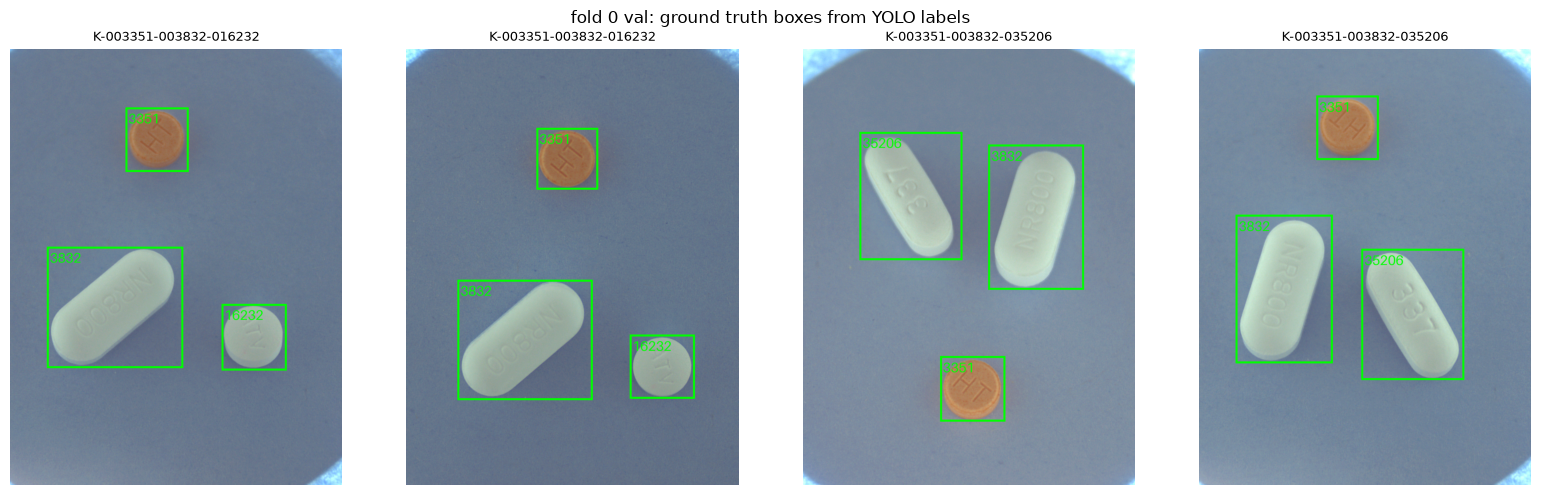

In [14]:
from PIL import Image as PILImage
from PIL import ImageDraw

check_class_map = load_class_map(LABEL)
idx_to_code = dict(zip(check_class_map["yolo_idx"], check_class_map["category_id"], strict=True))
sample_images = val_images[folds[0]][:4]
fig, axes = plt.subplots(1, len(sample_images), figsize=(4 * len(sample_images), 5), squeeze=False)
for ax, image_path in zip(axes[0], sample_images, strict=True):
    img = PILImage.open(image_path).convert("RGB")
    txt_path = yolo_dir(LABEL) / "labels" / "train" / f"{image_path.stem}.txt"
    draw = ImageDraw.Draw(img)
    for b in read_yolo_labels(txt_path, *img.size).itertuples():
        draw.rectangle([b.x, b.y, b.x + b.w, b.y + b.h], outline="lime", width=6)
        draw.text((b.x + 8, b.y + 8), str(idx_to_code[b.yolo_idx]), fill="lime", font_size=40)
    ax.imshow(img)
    ax.set_title(image_path.name.split("_")[0], fontsize=9)
    ax.axis("off")
fig.suptitle(f"fold {folds[0]} val: ground truth boxes from YOLO labels")
plt.tight_layout()
plt.show()

### 5-2. AI Hub 외부 데이터 추가 (02_eda §7)

> 출처: **02_eda** §1·2·5·6·7·8의 선별·검사 코드 — 사진 통째 사용, 외부 전용 알약 배경 처리, YOLO 변환, fold별 train 목록은 이 노트북에서 추가

`02_eda.ipynb` §7과 같은 방법·seed로 외부 bbox를 고르고, 그 bbox가 든 사진을 모든 fold의 train에 더합니다. val은 대회 사진 그대로입니다.

1. **선별 (02_eda §5~7)**: 대회 v1 라벨과 공통인 클래스마다 `AIHUB_TARGET_BBOX`(157)개가 되도록 부족한 수만큼 seed 42로 bbox를 뽑습니다. 좌표 오류·같은 약 중복 라벨이 있는 사진과 대회 사진과 이름이 같은 사진은 후보에서 뺍니다.
2. **문제 사진 제외 (02_eda §8)**: 파일명의 약 코드와 라벨이 다르거나(라벨 누락·파일명에 없는 라벨), bbox끼리 겹치거나(IoU > 0), 좌표가 잘못된 사진은 뺍니다. 02_eda §10~11의 OpenCV 보정은 사람 검수 전이라 적용하지 않습니다. JSON의 사진 크기와 실제 크기가 다른 사진, 대회 사진과 약 조합이 같은 사진(val 누수 가능)도 뺍니다.
3. **라벨**: 사진을 통째로 쓰므로 선택하지 않은 대회 알약도 모두 라벨링합니다. 그래서 클래스별 bbox는 157개를 넘을 수 있습니다. 대회 56종에 없는 **외부 전용 알약도 배경이 아닌 새 클래스로 라벨링**합니다 (`AIHUB_EXTRA_AS_CLASS = True`). 대회 번호 뒤에 0부터 이어지는 번호를 주고, `False`면 라벨 없이 배경으로 둡니다.
4. **YOLO 변환**: 외부 사진의 링크와 txt는 `data/processed/yolo/v1_aihub/`에 따로 만들고 파이프라인 폴더(`yolo/v1`)는 건드리지 않습니다. fold마다 `train.txt`는 대회 train + 외부 사진이고, `val.txt`는 파이프라인 파일을 그대로 씁니다. 외부 전용 클래스가 있으면 `data.yaml`의 `nc`·`names`를 대회 56종 뒤로 늘립니다.

선별 결과는 받은 zip에 따라 달라집니다. 이미지(TS) zip이 적으면 후보가 줄어 02_eda 머리말의 숫자(7,803 bbox / 5,499장)보다 적게 나옵니다. 실제로 쓴 bbox·라벨 목록은 `v1_aihub/aihub_selected.csv`·`aihub_labels.csv`에 저장하고, 검사 결과는 run 폴더의 `data_audit.json` → `aihub`에 남습니다.

Colab에서는 `AIHUB_URL`에서 zip을 받아 풉니다. 이미 받았거나 다 푼 zip은 건너뜁니다. 로컬은 02_eda처럼 이미 푼 폴더(`.env`의 `AIHUB_EXTRACT_DIR`, 없으면 `data/external/aihub_combo`)만 씁니다.

In [15]:
from data_process.aihub_data import (
    download_drive_folder,
    extract_zips,
    find_combo_zips,
    list_combo_images,
    load_combo_annotations,
    zip_key,
)

# 02_eda와 같은 위치. Colab은 올린 .env에 로컬 경로가 있어도 쓰지 않고 런타임 디스크를 쓴다.
aihub_extract_env = None if IN_COLAB else os.getenv("AIHUB_EXTRACT_DIR")
aihub_extract_dir = Path(aihub_extract_env or "data/external/aihub_combo").expanduser()
if not aihub_extract_dir.is_absolute():
    aihub_extract_dir = PROJECT_ROOT / aihub_extract_dir


def aihub_folders() -> list[Path]:
    """다 푼 외부 데이터 폴더 중 AIHUB_EXCLUDE에 없는 폴더를 이름순으로 반환한다 (02_eda §1)."""
    if not aihub_extract_dir.is_dir():
        return []
    return sorted(
        folder
        for folder in aihub_extract_dir.iterdir()
        if folder.is_dir()
        and not folder.name.startswith(".")
        and zip_key(folder) not in AIHUB_EXCLUDE
    )


if USE_AIHUB and IN_COLAB:
    if AIHUB_COLAB_ZIP_DIR:
        aihub_zip_dir = Path(AIHUB_COLAB_ZIP_DIR)
    else:
        if not os.getenv("AIHUB_URL"):
            from getpass import getpass

            os.environ["AIHUB_URL"] = getpass(
                "AI Hub zip 폴더의 Drive 링크 AIHUB_URL (화면에 표시되지 않음): "
            ).strip()
        if not os.environ["AIHUB_URL"]:
            raise RuntimeError(
                "AIHUB_URL이 필요합니다. /content/.env 또는 Colab 보안 비밀에 등록하세요."
            )
        # 이미 받은 파일은 건너뛰고 끊긴 파일은 이어 받는다
        aihub_zip_dir = download_drive_folder(
            os.environ["AIHUB_URL"], PROJECT_ROOT / "data" / "external" / "aihub_zips"
        )
    aihub_zips = find_combo_zips(aihub_zip_dir, exclude=AIHUB_EXCLUDE)
    if not aihub_zips:
        raise FileNotFoundError(f"경로에 '조합'이 들어간 zip이 없습니다: {aihub_zip_dir}")
    print(f"조합 zip {len(aihub_zips)}개: {', '.join(path.name for path in aihub_zips)}")
    extract_zips(aihub_zips, aihub_extract_dir)  # 이미 다 푼 zip은 건너뛴다

aihub_dirs = aihub_folders() if USE_AIHUB else []
if USE_AIHUB and not aihub_dirs:
    raise FileNotFoundError(
        f"압축을 푼 외부 데이터 폴더가 없습니다: {aihub_extract_dir}. "
        "로컬은 02_eda처럼 미리 풀어 두고, Colab은 AIHUB_URL을 확인하세요."
    )
if USE_AIHUB:
    print(f"외부 데이터 {aihub_extract_dir}: {', '.join(folder.name for folder in aihub_dirs)}")
else:
    print("USE_AIHUB=False: 외부 데이터 없이 대회 데이터만 학습합니다.")

외부 데이터 /mnt/c/AI/test/pill-bbox/data/external/aihub_combo: TL_1_조합, TL_3_조합, TL_4_조합, TL_5_조합, TL_6_조합, TL_7_조합, TL_8_조합, TS_1_조합, TS_3_조합, TS_4_조합, TS_5_조합, TS_6_조합, TS_7_조합, TS_8_조합, VL_1_조합, VS_1_조합


항목,개수
외부 이미지 (푼 폴더 전체),16012
외부 bbox 라벨 (푼 폴더 전체),45933
공통 클래스 (대회 v1 ∩ 외부),54
02_eda §7 선택 bbox,7900
선택 bbox가 든 사진,5937
제외: 라벨 누락,21
제외: 파일명에 없는 라벨,0
제외: bbox 겹침,74
제외: 좌표·중복 오류,0
제외: JSON·실제 크기 다름,0


합계가 목표 157개 미만인 클래스: 2/56종


,dl_name,대회 v1,02_eda 선택,외부 학습 라벨,합계
category_id,,,,,
3743,알드린정,3,154,252,255
13395,써스펜8시간이알서방정 650mg,3,154,217,220
12247,아빌리파이정 10mg,3,154,246,249
12081,리렉스펜정 300mg/PTP,3,154,215,218
22362,맥시부펜이알정 300mg,3,154,191,194
21771,라비에트정 20mg,3,154,226,229
19552,트루비타정 60mg/병,3,154,242,245
16551,동아가바펜틴정 800mg,3,154,789,792
33009,신바로정,3,154,234,237


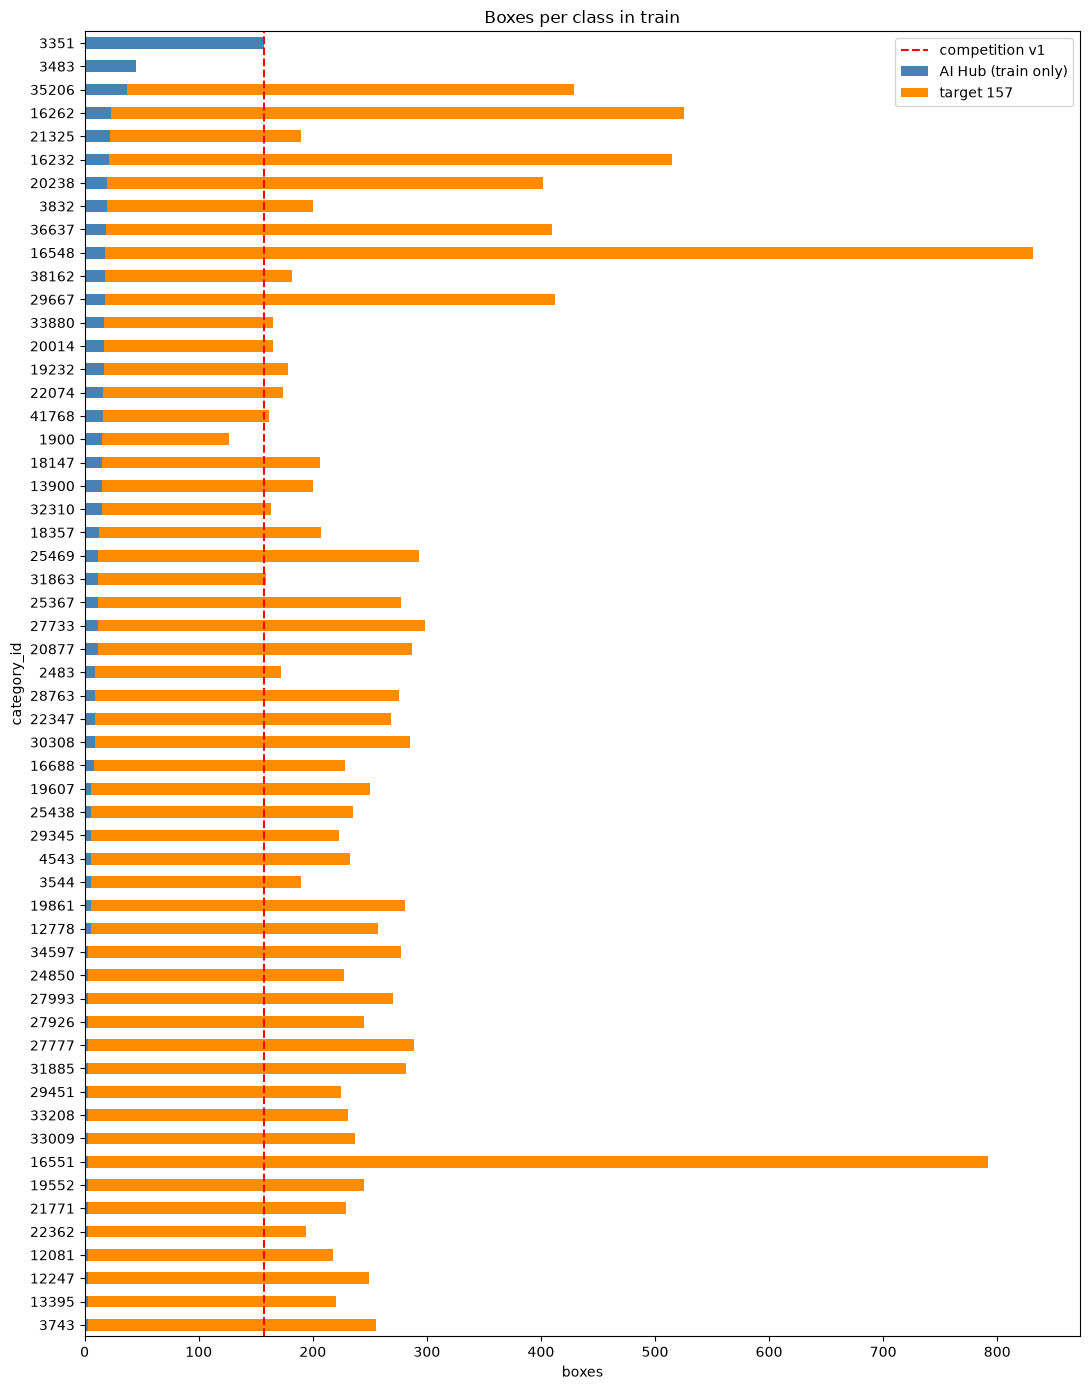

In [16]:
from data_process.data_processing import (
    bbox_flags,
    find_box_pairs,
    list_images,
    read_image_headers,
)

BOX_NUMBERS = ["x", "y", "w", "h", "width", "height"]
aihub_raw_dir = PROJECT_ROOT / "data" / "raw"
if (aihub_raw_dir / "sprint_ai_project1_data").is_dir():
    aihub_raw_dir = aihub_raw_dir / "sprint_ai_project1_data"


def name_codes(file_name: str) -> set[int]:
    """파일명 앞 조합(K-001900-003544-...)의 약 코드 집합. 사진에서 센 알약 수가 아니다."""
    return {int(code) for code in file_name.split("_")[0].split("-")[1:]}


def select_aihub_images(dirs: list[Path], comp_labels: pd.DataFrame) -> dict:
    """02_eda §1·2·5·6·7과 같이 bbox를 고르고 §8 검사로 쓸 사진·라벨·배경 알약을 나눈다."""
    # §1·2: 이미지와 라벨 연결. 같은 이름이 여러 폴더에 있으면 라벨을 안전하게 붙일 수 없다.
    image_index = list_combo_images(dirs)
    if image_index.empty:
        raise FileNotFoundError("외부 이미지가 없습니다. TS 원천 이미지 폴더를 확인하세요.")
    if image_index["file_name"].duplicated().any():
        raise ValueError("외부 이미지 이름이 중복됩니다. 02_eda §1에서 중복 목록을 확인하세요.")
    ann_df, _ = load_combo_annotations(dirs)
    if ann_df.empty or ann_df["category_id"].isna().any():
        raise ValueError("외부 라벨이 없거나 약 코드를 해석할 수 없는 bbox가 있습니다 (02_eda §2).")
    available = ann_df[ann_df["file_name"].isin(set(image_index["file_name"]))].copy()

    # §5: 대회 v1과 공통인 클래스마다 목표까지 부족한 bbox 수
    comp_counts = comp_labels.groupby("category_id").size()
    common = sorted(set(comp_counts.index) & set(available["category_id"].astype(int)))
    needed = (AIHUB_TARGET_BBOX - comp_counts).clip(lower=0)

    # §6: 좌표·중복 오류가 있는 사진과 대회 사진과 같은 이름은 후보에서 뺀다
    candidates = available[available["category_id"].isin(common)].merge(
        image_index[["file_name", "path"]], on="file_name", validate="many_to_one"
    )
    numeric = available[BOX_NUMBERS].apply(pd.to_numeric, errors="coerce")
    flags = bbox_flags(available)
    invalid_box = (
        ~np.isfinite(numeric).all(axis=1)
        | numeric[["width", "height"]].le(0).any(axis=1)
        | flags["out_of_image"]
        | flags["non_positive"]
        | available.duplicated(["file_name", "category_id"], keep=False)
    )
    invalid_files = set(available.loc[invalid_box, "file_name"])
    comp_names = {
        path.name
        for split in ("train", "test")
        for path in list_images(aihub_raw_dir / f"{split}_images")
    }
    comp_combos = set(comp_labels["file_name"].str.split("_").str[0])
    comp_combos |= {name.split("_")[0] for name in comp_names if name.startswith("K-")}

    # §7: 클래스별 부족량만큼 seed로 비복원 추출한다
    pool = candidates[~candidates["file_name"].isin(invalid_files | comp_names)].copy()
    pool["combo"] = pool["file_name"].str.split("_").str[0]
    pool["shares_competition_combo"] = pool["combo"].isin(comp_combos)
    pool = pool.drop_duplicates(["file_name", "category_id", "x", "y", "w", "h"])
    shuffled = pool.sample(frac=1, random_state=SEED)
    order = shuffled.groupby("category_id").cumcount()
    selected = (
        shuffled[order.lt(shuffled["category_id"].map(needed))]
        .sort_values(["category_id", "file_name"])
        .reset_index(drop=True)
    )

    # §8: 선택 bbox가 든 사진 전체의 라벨을 검사한다. 사진을 통째로 쓰므로 함께 찍힌 bbox도 본다.
    files = sorted(selected["file_name"].unique())
    boxes = available[available["file_name"].isin(files)].copy()
    boxes["category_id"] = boxes["category_id"].astype(int)
    numeric = boxes[BOX_NUMBERS].apply(pd.to_numeric, errors="coerce")
    valid = np.isfinite(numeric).all(axis=1) & numeric[["w", "h", "width", "height"]].gt(0).all(
        axis=1
    )
    invalid = (
        ~valid
        | bbox_flags(boxes)["out_of_image"]
        | boxes.duplicated(["file_name", "category_id"], keep=False)
    )
    pairs = find_box_pairs(boxes[valid], max_gap=0)
    labeled = boxes.groupby("file_name")["category_id"].agg(set)
    paths = image_index.set_index("file_name")["path"]
    headers = read_image_headers([paths[name] for name in files], "aihub").set_index("file_name")
    json_size = boxes.groupby("file_name")[["width", "height"]].first()
    reasons = pd.DataFrame(index=pd.Index(files, name="file_name"))
    reasons["라벨 누락"] = [bool(name_codes(name) - labeled[name]) for name in files]
    reasons["파일명에 없는 라벨"] = [bool(labeled[name] - name_codes(name)) for name in files]
    reasons["bbox 겹침"] = reasons.index.isin(set(pairs.loc[pairs["iou"].gt(0), "file_name"]))
    reasons["좌표·중복 오류"] = reasons.index.isin(set(boxes.loc[invalid, "file_name"]))
    real_size = headers.loc[files, ["width", "height"]].to_numpy()
    reasons["JSON·실제 크기 다름"] = (real_size != json_size.loc[files].to_numpy()).any(axis=1)
    # 대회 사진과 약 조합이 같으면 같은 조합의 대회 val 사진과 겹칠 수 있다
    reasons["대회와 같은 조합"] = reasons.index.str.split("_").str[0].isin(comp_combos)

    comp_ids = set(comp_labels["category_id"].astype(int))
    kept = boxes[boxes["file_name"].isin(reasons.index[~reasons.any(axis=1)])]
    return {
        "n_images": len(image_index),
        "n_labels": len(ann_df),
        "common_classes": common,
        "selected": selected,
        "reasons": reasons,
        "labels": kept[kept["category_id"].isin(comp_ids)].copy(),
        "background": kept[~kept["category_id"].isin(comp_ids)].copy(),
        "paths": paths,
    }


if USE_AIHUB:
    comp_labels = pd.read_csv(PROJECT_ROOT / "data/processed/labels" / f"labels_{LABEL}.csv")
    aihub = select_aihub_images(aihub_dirs, comp_labels)
    aihub_labels, aihub_reasons = aihub["labels"], aihub["reasons"]
    aihub_files = sorted(aihub_labels["file_name"].unique())
    if aihub_files != sorted(aihub_reasons.index[~aihub_reasons.any(axis=1)]):
        raise ValueError("대회 클래스 라벨이 없는 외부 사진이 있습니다.")
    aihub_summary = [
        ("외부 이미지 (푼 폴더 전체)", aihub["n_images"]),
        ("외부 bbox 라벨 (푼 폴더 전체)", aihub["n_labels"]),
        ("공통 클래스 (대회 v1 ∩ 외부)", len(aihub["common_classes"])),
        ("02_eda §7 선택 bbox", len(aihub["selected"])),
        ("선택 bbox가 든 사진", len(aihub_reasons)),
        *[(f"  제외: {column}", int(aihub_reasons[column].sum())) for column in aihub_reasons],
        ("제외한 사진 (사유가 여럿이어도 한 번)", int(aihub_reasons.any(axis=1).sum())),
        ("train에 더할 사진", len(aihub_files)),
        ("학습 라벨 bbox (대회 클래스, 선택 + 함께 찍힌 것)", len(aihub_labels)),
        ("외부 전용 알약 (새 클래스 또는 배경)", len(aihub["background"])),
    ]
    display(pd.DataFrame(aihub_summary, columns=["항목", "개수"]).style.hide(axis="index"))

    aihub_classes = load_class_map(LABEL).set_index("category_id")[["dl_name"]]
    aihub_classes["대회 v1"] = comp_labels.groupby("category_id").size()
    aihub_classes["02_eda 선택"] = aihub["selected"].groupby("category_id").size()
    aihub_classes["외부 학습 라벨"] = aihub_labels.groupby("category_id").size()
    count_columns = ["대회 v1", "02_eda 선택", "외부 학습 라벨"]
    aihub_classes[count_columns] = aihub_classes[count_columns].fillna(0).astype(int)
    aihub_classes["합계"] = aihub_classes["대회 v1"] + aihub_classes["외부 학습 라벨"]
    aihub_classes = aihub_classes.sort_values("대회 v1")
    n_short = int(aihub_classes["합계"].lt(AIHUB_TARGET_BBOX).sum())
    print(f"합계가 목표 {AIHUB_TARGET_BBOX}개 미만인 클래스: {n_short}/{len(aihub_classes)}종")
    with pd.option_context("display.max_rows", None):
        display(aihub_classes)
    ax = aihub_classes[["대회 v1", "외부 학습 라벨"]].plot.barh(
        stacked=True, figsize=(11, 14), color=["steelblue", "darkorange"]
    )
    ax.axvline(AIHUB_TARGET_BBOX, color="red", linestyle="--")
    ax.legend(["competition v1", "AI Hub (train only)", f"target {AIHUB_TARGET_BBOX}"])
    ax.set(title="Boxes per class in train", xlabel="boxes", ylabel="category_id")
    plt.tight_layout()
    plt.show()

In [17]:
from data_process.make_labels import write_yolo_labels
from data_process.move_files import link_images

AIHUB_YOLO_DIR = yolo_dir(f"{LABEL}_aihub")  # data/processed/yolo/v1_aihub. 파이프라인 폴더와 따로
aihub_image_dir = AIHUB_YOLO_DIR / "images" / "train"
aihub_label_dir = AIHUB_YOLO_DIR / "labels" / "train"


def list_path(data: dict, split: str) -> Path:
    """data.yaml의 train·val 목록 파일 경로."""
    path = Path(data[split])
    return path if path.is_absolute() else Path(data["path"]) / path


def read_list(path: Path) -> list[str]:
    """목록 txt의 이미지 경로를 빈 줄 없이 읽는다."""
    return [line.strip() for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]


train_data_paths = {}
# 외부 전용 알약 클래스 표. AIHUB_EXTRA_AS_CLASS일 때만 아래 else 블록에서 채운다
aihub_extra_map = pd.DataFrame(
    {
        "yolo_idx": pd.Series(dtype=int),
        "category_id": pd.Series(dtype=int),
        "dl_name": pd.Series(dtype=str),
    }
)
aihub_extra_names = {}
if not USE_AIHUB:
    train_data_paths = dict(data_paths)
    data_audit["aihub"] = {"used": False, "folds": list(folds)}
else:
    # 외부 사진 링크와 YOLO 라벨. 외부 전용 알약은 설정에 따라 새 클래스 또는 배경이다.
    aihub_class_map = load_class_map(LABEL)
    aihub_class_idx = dict(
        zip(
            aihub_class_map["category_id"].astype(int),
            aihub_class_map["yolo_idx"].astype(int),
            strict=True,
        )
    )
    # 외부 전용 알약: 배경이 아니라 대회 클래스 수 뒤의 새 번호로 라벨링한다 (끄면 라벨 없이 배경)
    aihub_train_labels = aihub_labels
    if AIHUB_EXTRA_AS_CLASS:
        extra = aihub["background"].drop_duplicates("category_id").sort_values("category_id")
        aihub_extra_map = pd.DataFrame(
            {
                "yolo_idx": range(len(aihub_class_map), len(aihub_class_map) + len(extra)),
                "category_id": extra["category_id"].astype(int).to_numpy(),
                "dl_name": extra["dl_name"].to_numpy(),
            }
        )
        extra_ids = aihub_extra_map["yolo_idx"].tolist()
        aihub_extra_names = dict(zip(extra_ids, aihub_extra_map["dl_name"].tolist(), strict=True))
        aihub_class_idx.update(zip(aihub_extra_map["category_id"].tolist(), extra_ids, strict=True))
        aihub_train_labels = pd.concat([aihub_labels, aihub["background"]], ignore_index=True)
    link_counts = link_images([aihub["paths"][name] for name in aihub_files], aihub_image_dir)
    yolo_counts = write_yolo_labels(
        aihub_train_labels, aihub_files, aihub_class_idx, aihub_label_dir
    )
    aihub_manifest = []
    max_error = 0.0
    yolo_columns = ["yolo_idx", "x", "y", "w", "h"]
    for file_name, rows in aihub_train_labels.groupby("file_name"):
        txt_path = aihub_label_dir / Path(file_name).with_suffix(".txt").name
        back = read_yolo_labels(txt_path, rows["width"].iloc[0], rows["height"].iloc[0])
        expected = rows.assign(yolo_idx=rows["category_id"].map(aihub_class_idx))
        if len(back) != len(expected) or expected["yolo_idx"].isna().any():
            raise ValueError(f"외부 YOLO 라벨 개수나 클래스가 다릅니다: {file_name}")
        error = np.abs(
            back[yolo_columns].sort_values(yolo_columns).to_numpy(dtype=float)
            - expected[yolo_columns].sort_values(yolo_columns).to_numpy(dtype=float)
        ).max()
        max_error = max(max_error, float(error))
        aihub_manifest.append(txt_path)
    if (
        max_error > 0.01
        or yolo_counts["n_dropped"]
        or yolo_counts["n_empty"]
        or yolo_counts["n_lines"] != len(aihub_train_labels)
    ):
        raise ValueError(f"외부 YOLO 라벨 검사 실패: {yolo_counts}, 오차={max_error}px")

    # 실제로 쓴 선택 bbox와 학습 라벨을 남긴다
    keep_columns = [
        "file_name",
        "zip_name",
        "source_json",
        "annotation_id",
        "category_id",
        "dl_name",
        *BOX_NUMBERS,
    ]
    for name, frame in [
        ("aihub_selected", aihub["selected"]),
        ("aihub_labels", aihub_train_labels),
    ]:
        frame[keep_columns].to_csv(AIHUB_YOLO_DIR / f"{name}.csv", index=False, encoding="utf-8")
        aihub_manifest.append(AIHUB_YOLO_DIR / f"{name}.csv")

    # fold마다 train = 대회 train + 외부 사진, val = 파이프라인 val.txt 그대로
    aihub_images = [str(aihub_image_dir / name) for name in aihub_files]
    aihub_combos = {name.split("_")[0] for name in aihub_files}
    aihub_fold_rows = []
    for fold in folds:
        base = yaml.safe_load(data_paths[fold].read_text(encoding="utf-8"))
        comp_train = read_list(list_path(base, "train"))
        val_path = list_path(base, "val")
        val_names = {Path(line).name for line in read_list(val_path)}
        comp_names = val_names | {Path(line).name for line in comp_train}
        val_combos = {name.split("_")[0] for name in val_names}
        if set(aihub_files) & comp_names or aihub_combos & val_combos:
            raise ValueError(f"fold {fold}: 외부 사진이 대회 사진이나 val 조합과 겹칩니다.")
        out_dir = AIHUB_YOLO_DIR / "splits" / SPLIT / f"fold_{fold}"
        out_dir.mkdir(parents=True, exist_ok=True)
        train_txt = out_dir / "train.txt"
        train_txt.write_text(
            "".join(f"{path}\n" for path in comp_train + aihub_images), encoding="utf-8"
        )
        names = {**base["names"], **aihub_extra_names}
        data = {
            "path": base["path"],
            "train": str(train_txt),
            "val": str(val_path),
            "nc": len(names),
            "names": names,
        }
        header = {
            "label_version": LABEL,
            "split_name": SPLIT,
            "fold": fold,
            "aihub_images": len(aihub_images),
            "extra_classes": len(aihub_extra_names),
        }
        yaml_path = out_dir / "data.yaml"
        yaml_path.write_text(
            "".join(f"# {key}: {value}\n" for key, value in header.items())
            + yaml.safe_dump(data, allow_unicode=True, sort_keys=False),
            encoding="utf-8",
        )
        train_data_paths[fold] = yaml_path
        aihub_manifest.extend([train_txt, yaml_path])
        n_train = len(comp_train) + len(aihub_images)
        aihub_fold_rows.append(
            {
                "fold": fold,
                "대회 train": len(comp_train),
                "외부 train": len(aihub_images),
                "train 합계": n_train,
                "val (대회)": len(val_names),
                "train 배수": round(n_train / len(comp_train), 1),
            }
        )

    # 학습 셀의 데이터 지문 검사에 외부 라벨·목록도 넣는다. 다시 실행해도 이전 외부 파일은 뺀다.
    aihub_prefix = AIHUB_YOLO_DIR.relative_to(PROJECT_ROOT).as_posix() + "/"
    data_audit["files"] = sorted(
        {name for name in data_audit["files"] if not name.startswith(aihub_prefix)}
        | {path.relative_to(PROJECT_ROOT).as_posix() for path in aihub_manifest}
    )
    data_audit["fingerprint"] = files_sha256(
        [PROJECT_ROOT / name for name in data_audit["files"]], PROJECT_ROOT
    )
    data_audit["aihub"] = {
        "used": True,
        "source": "notebooks/02_eda.ipynb §1·2·5·6·7·8",
        "folds": list(folds),
        "folders": [folder.name for folder in aihub_dirs],
        "exclude": list(AIHUB_EXCLUDE),
        "target_bbox": AIHUB_TARGET_BBOX,
        "seed": SEED,
        "selected_bbox": len(aihub["selected"]),
        "selected_images": len(aihub_reasons),
        "excluded_images": {column: int(aihub_reasons[column].sum()) for column in aihub_reasons},
        "train_images": len(aihub_files),
        "train_labels": len(aihub_train_labels),
        "extra_classes": len(aihub_extra_names),
        "background_pills": len(aihub["background"]),
        "background_policy": (
            "대회 56종 밖 외부 전용 알약은 새 클래스로 학습"
            if AIHUB_EXTRA_AS_CLASS
            else "대회 56종에 없는 외부 전용 알약은 라벨 없이 배경으로 둔다"
        ),
        "yolo_dir": aihub_prefix.rstrip("/"),
        "yolo_max_roundtrip_error_px": max_error,
        "fold_counts": aihub_fold_rows,
    }
    print(
        f"외부 사진 링크 {link_counts}, YOLO 라벨 {yolo_counts}, 역변환 최대 오차 {max_error:.4f}px"
    )
    print("외부 사진과 대회 사진·val 조합 겹침 0 확인. val은 파이프라인 val.txt 그대로입니다.")
    display(pd.DataFrame(aihub_fold_rows))
    print("에폭당 학습 시간은 train 사진 수에 비례해 대략 'train 배수'만큼 늘어납니다.")

외부 사진 링크 {'symlink': 0, 'copy': 0, 'kept': 5842}, YOLO 라벨 {'n_txt': 5842, 'n_lines': 21720, 'n_dropped': 0, 'n_empty': 0}, 역변환 최대 오차 0.0010px
외부 사진과 대회 사진·val 조합 겹침 0 확인. val은 파이프라인 val.txt 그대로입니다.


,fold,대회 train,외부 train,train 합계,val (대회),train 배수
0,0,195,5842,6037,37,31.0
1,1,193,5842,6035,39,31.3
2,2,192,5842,6034,40,31.4
3,3,194,5842,6036,38,31.1
4,4,193,5842,6035,39,31.3


에폭당 학습 시간은 train 사진 수에 비례해 대략 'train 배수'만큼 늘어납니다.


#### 외부 사진 눈으로 확인

외부 train 사진 4장에 YOLO txt에서 되돌린 박스를 그립니다. 초록은 학습 라벨입니다. `AIHUB_EXTRA_AS_CLASS = True`면 외부 전용 알약도 초록 라벨(대회 번호 뒤의 새 클래스)로 표시합니다. `False`면 라벨 없이 배경으로 둔 외부 전용 알약을 회색 `bg`로만 표시하고, 회색 박스는 학습에 들어가지 않습니다.

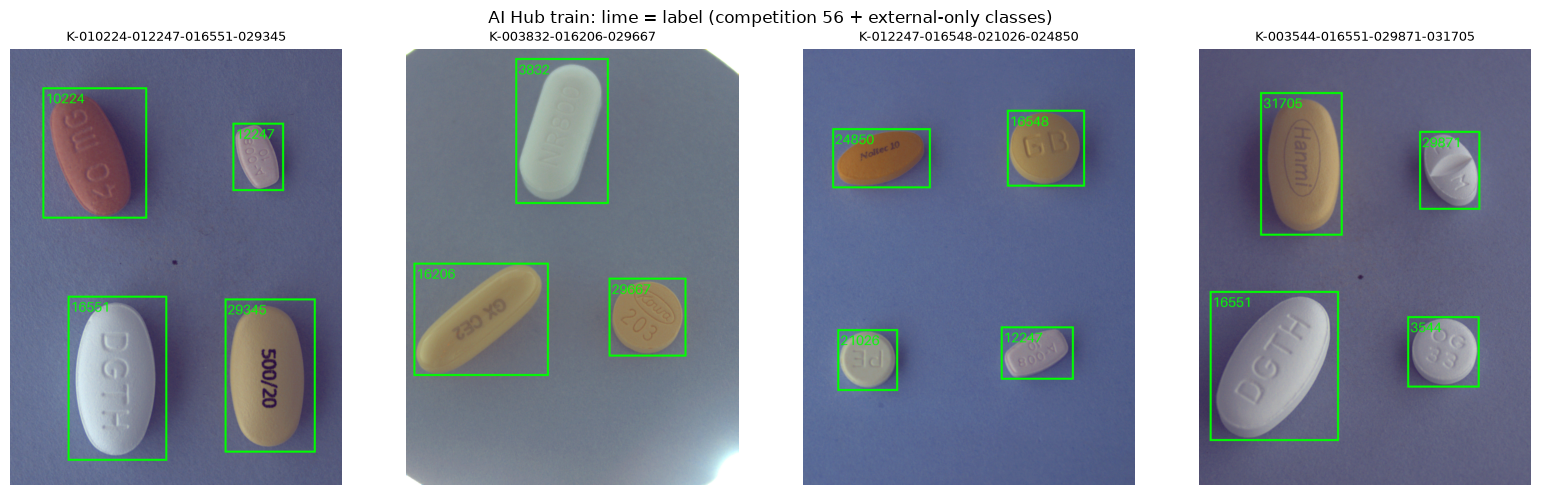

In [18]:
from PIL import Image as PILImage
from PIL import ImageDraw

if USE_AIHUB:
    aihub_idx_to_code = {index: code for code, index in aihub_class_idx.items()}
    # 배경 알약이 있는 사진을 먼저 보여 준다
    preview_pool = sorted(set(aihub["background"]["file_name"])) or aihub_files
    preview_files = pd.Series(preview_pool).sample(n=min(4, len(preview_pool)), random_state=SEED)
    fig, axes = plt.subplots(
        1, len(preview_files), figsize=(4 * len(preview_files), 5), squeeze=False
    )
    for ax, file_name in zip(axes[0], preview_files, strict=True):
        img = PILImage.open(aihub_image_dir / file_name).convert("RGB")
        draw = ImageDraw.Draw(img)
        txt_path = aihub_label_dir / Path(file_name).with_suffix(".txt").name
        for b in read_yolo_labels(txt_path, *img.size).itertuples():
            draw.rectangle([b.x, b.y, b.x + b.w, b.y + b.h], outline="lime", width=6)
            label = str(aihub_idx_to_code[b.yolo_idx])
            draw.text((b.x + 8, b.y + 8), label, fill="lime", font_size=40)
        background = aihub["background"][aihub["background"]["file_name"].eq(file_name)]
        if AIHUB_EXTRA_AS_CLASS:  # 외부 전용 알약도 위에서 초록 라벨로 그렸다
            background = background.iloc[0:0]
        for b in background.itertuples():
            draw.rectangle([b.x, b.y, b.x + b.w, b.y + b.h], outline="gray", width=4)
            draw.text((b.x + 8, b.y + 8), f"bg {b.category_id}", fill="gray", font_size=40)
        ax.imshow(img)
        ax.set_title(file_name.split("_")[0], fontsize=9)
        ax.axis("off")
    fig.suptitle(
        "AI Hub train: lime = label (competition 56 + external-only classes)"
        if AIHUB_EXTRA_AS_CLASS
        else "AI Hub train: lime = label (competition class), gray = background (external-only)"
    )
    plt.tight_layout()
    plt.show()

## 6. fold별 train·validation 검사
같은 8:2 무작위 분할을 반복하지 않고 기존 파이프라인의 서로 다른 5 fold를 사용합니다. 희귀 조합은 모든 fold의 train에 고정합니다. 대회 데이터의 train·val 비율은 조합 크기와 고정 정책에 따라 달라집니다. 외부 이미지는 모든 fold의 train에만 사용합니다.


In [19]:
fold_data_paths = {fold: Path(train_data_paths[fold]) for fold in folds}
fold_splits, fold_manifests = {}, {}
validation_sets = {}
fold_counts = []
for fold, data_path in fold_data_paths.items():
    data = yaml.safe_load(data_path.read_text(encoding="utf-8"))
    original = pd.read_csv(PROJECT_ROOT / "data/processed/splits" / SPLIT / f"fold_{fold}.csv")
    competition_files = set(original["file_name"])
    flags = original["fixed"].astype(str).str.lower().isin(["true", "1"])
    fixed_files = set(original.loc[flags, "file_name"])
    records = []
    for split in ["train", "val"]:
        for value in read_list(list_path(data, split)):
            path = Path(value)
            records.append(
                {
                    "fold": fold,
                    "path": str(path),
                    "file_name": path.name,
                    "combo": path.name.split("_")[0],
                    "split": split,
                    "data_source": "competition" if path.name in competition_files else "external",
                    "fixed": path.name in fixed_files,
                }
            )
    table = pd.DataFrame(records).sort_values(["split", "file_name"]).reset_index(drop=True)
    if table["file_name"].duplicated().any():
        raise ValueError(f"fold {fold}: 이미지 중복 또는 train/val 중복이 있습니다.")
    train = table.loc[table["split"].eq("train")]
    val = table.loc[table["split"].eq("val")]
    if val.empty or not val["data_source"].eq("competition").all():
        raise ValueError(f"fold {fold}: 검증은 대회 이미지만 있어야 합니다.")
    if not table.loc[table["data_source"].eq("external"), "split"].eq("train").all():
        raise ValueError(f"fold {fold}: 외부 이미지가 val에 들어갔습니다.")
    if set(train["combo"]) & set(val["combo"]):
        raise ValueError(f"fold {fold}: train/val 조합이 겹칩니다.")
    if set(val["file_name"]) != set(original.loc[original["split"].eq("val"), "file_name"]):
        raise ValueError(f"fold {fold}: 기존 fold의 검증 목록이 달라졌습니다.")
    if not fixed_files.issubset(set(train["file_name"])):
        raise ValueError(f"fold {fold}: 희귀 조합 train 고정이 깨졌습니다.")
    validation_sets[fold] = set(val["file_name"])
    fold_splits[fold] = table
    fold_manifests[fold] = {
        "fold": fold,
        "source_split": SPLIT,
        "seed": SEED,
        "source_yaml": str(data_path),
        "external_train_only": True,
        "combo_overlap": 0,
        "counts": table.groupby(["data_source", "split"])
        .size()
        .rename("images")
        .reset_index()
        .to_dict("records"),
    }
    fold_counts.append(
        {
            "fold": fold,
            "competition_train": int(train["data_source"].eq("competition").sum()),
            "external_train": int(train["data_source"].eq("external").sum()),
            "val": len(val),
        }
    )
for first, first_files in validation_sets.items():
    for second, second_files in validation_sets.items():
        if first < second and first_files & second_files:
            raise ValueError(f"fold {first}와 {second}의 검증 이미지가 겹칩니다.")
external_sets = [
    set(table.loc[table["data_source"].eq("external"), "file_name"])
    for table in fold_splits.values()
]
if external_sets and any(files != external_sets[0] for files in external_sets):
    raise ValueError("fold마다 외부 학습 이미지가 다릅니다.")
if set(folds) == set(range(5)):
    free_files = set(original.loc[~flags, "file_name"])
    if set().union(*validation_sets.values()) != free_files:
        raise ValueError("5 fold 검증이 train 고정 외의 대회 이미지를 모두 포함하지 않습니다.")
display(pd.DataFrame(fold_counts))
print("각 fold의 검증 이미지는 서로 다르고, 외부 이미지는 모든 fold의 train에 포함됩니다.")

,fold,competition_train,external_train,val
0,0,195,5842,37
1,1,193,5842,39
2,2,192,5842,40
3,3,194,5842,38
4,4,193,5842,39


각 fold의 검증 이미지는 서로 다르고, 외부 이미지는 모든 fold의 train에 포함됩니다.


## 7. 로컬 실행 설정
학습 하이퍼파라미터는 위 설정 셀의 값을 그대로 사용합니다. 결과는 v5 전용 폴더에 저장합니다.


In [20]:
RUN_YOLO_TRAIN = True
RESUME_TRAINING = True  # 중단된 fold 재개, 완료된 fold는 건너뛴다
RESUME_CHECKPOINTS = {}  # 후보가 여러 개일 때 지정: {2: Path(".../weights/last.pt")}
# 재사용 예: {0: Path(".../fold0/weights/best.pt"), 1: Path(".../fold1/weights/best.pt")}
YOLO_CHECKPOINTS = {}

experiment_dir = Path(output_root) / OUTPUT_NAME / f"yolo11m_v5_s{SEED}"
print("로컬 결과 폴더:", experiment_dir.resolve())

로컬 결과 폴더: /mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100_aihub_class/yolo11m_v5_s42


## 8. fold별 YOLO 학습 · validation
fold마다 새 사전학습 YOLO11m에서 시작해 독립적으로 학습합니다. mAP75-95 최고 best.pt와 기존 patience 조기 종료 설정을 유지합니다. 각 fold의 실제 모델 경로를 checkpoints에 기록합니다.
중단 시 epoch마다 저장하는 last.pt에서 optimizer·scheduler 학습 상태를 복원합니다. 설정·데이터·분할이 달라지면 재개를 차단합니다. RESUME_TRAINING=False이면 기존 실행을 덮어쓰지 않고 새 실행을 만듭니다.


In [21]:
class EpochTimer:
    """에폭별 학습·검증·체크포인트 저장 시간을 진행 바와 CSV로 기록한다."""

    def __init__(self, fold: int) -> None:
        self.fold = fold
        self.progress = None
        self.started_at: float | None = None
        self.active_epoch: int | None = None
        self.rows: list[dict] = []

    def on_train_start(self, trainer: DetectionTrainer) -> None:
        """배치 진행 바와 별도로 전체 에폭 진행 바를 시작한다."""
        self.progress = tqdm(
            total=trainer.epochs,
            initial=trainer.start_epoch,
            desc=f"fold {self.fold} / epochs",
            unit="epoch",
            dynamic_ncols=True,
            mininterval=TQDM_MININTERVAL,
            leave=True,
        )

    def on_epoch_start(self, trainer: DetectionTrainer) -> None:
        """에폭 재시도 시간이 빠지지 않도록 최초 시작 시각을 유지한다."""
        epoch = trainer.epoch + 1
        if self.active_epoch != epoch:
            self.active_epoch = epoch
            self.started_at = perf_counter()

    def on_epoch_end(self, trainer: DetectionTrainer) -> None:
        """검증과 저장이 끝나면 시간을 기록하고, 최종 best 재검증 호출은 제외한다."""
        if self.started_at is None:
            return
        seconds = perf_counter() - self.started_at
        self.started_at = None
        self.active_epoch = None
        epoch = trainer.epoch + 1
        elapsed = sum(row["epoch_seconds"] for row in self.rows) + seconds
        average = elapsed / (len(self.rows) + 1)
        remaining = max(trainer.epochs - epoch, 0) * average
        self.rows.append(
            {
                "epoch": epoch,
                "epoch_seconds": seconds,
                "cumulative_seconds": elapsed,
                "estimated_remaining_seconds": remaining,
            }
        )
        pd.DataFrame(self.rows).to_csv(Path(trainer.save_dir) / "epoch_times.csv", index=False)
        if self.progress is not None:
            self.progress.set_postfix(
                epoch_time=f"{seconds:.1f}s", remaining=f"{remaining / 60:.1f}min"
            )
            self.progress.update(max(epoch - self.progress.n, 0))
        LOGGER.info(
            f"fold {self.fold}, epoch {epoch}/{trainer.epochs}: "
            f"{seconds:.2f}초 (train + validation + checkpoint), "
            f"남은 예상 시간 {remaining / 60:.1f}분"
        )

    def close(self) -> None:
        """정상 종료와 오류 모두에서 진행 바를 정리한다."""
        if self.progress is not None:
            self.progress.close()

In [22]:
from models.fold_training import train_fold

# 설정 셀만 재실행해 fold 선택이 메모리에 이전 값으로 남는 경우를 막는다.
expected_folds = [FOLDS[0]] if SMOKE else list(FOLDS)
if list(folds) != expected_folds:
    raise RuntimeError("FOLDS 설정이 바뀌었습니다. 환경·데이터 준비·EDA 검사 셀을 다시 실행하세요.")

# EDA 검사 후 설정이나 입력 파일이 달라지면 학습을 시작하지 않는다.
if "data_audit" not in globals():
    raise RuntimeError("먼저 EDA 반영 확인 셀을 실행하세요.")
if (data_audit["label"], data_audit["split"], data_audit["folds"]) != (LABEL, SPLIT, list(folds)):
    raise RuntimeError("라벨·분할·fold 설정이 바뀌었습니다. EDA 검사를 다시 실행하세요.")
if data_audit["rare_policy"]["max_bboxes"] != RARE_BBOX_MAX:
    raise RuntimeError("희귀 약 기준이 바뀌었습니다. 데이터 생성과 EDA 검사를 다시 실행하세요.")
audited_files = [PROJECT_ROOT / name for name in data_audit["files"]]
if files_sha256(audited_files, PROJECT_ROOT) != data_audit["fingerprint"]:
    raise RuntimeError("EDA 검사 후 데이터가 바뀌었습니다. 데이터 준비와 검사를 다시 실행하세요.")

# 외부 데이터 셀(5-2) 뒤에 EDA 검사 셀을 다시 실행하면 외부 데이터 기록이 빠진다.
if (
    "train_data_paths" not in globals()
    or set(train_data_paths) != set(folds)
    or data_audit.get("aihub", {}).get("folds") != list(folds)
    or data_audit["aihub"]["used"] != USE_AIHUB
):
    raise RuntimeError("외부 데이터 셀(5-2)을 EDA 검사 셀 다음에 다시 실행하세요.")

# 커널 연결 후 장치 상태가 바뀐 경우를 반영한다.
device = get_device()
if RUN_YOLO_TRAIN and not SMOKE and device != "cuda":
    if torch.version.cuda is None:
        reason = (
            "현재 커널의 PyTorch는 CUDA 지원 빌드가 아닙니다. "
            "프로젝트 터미널에서 uv sync --locked 후, VS Code 오른쪽 위 커널 선택에서 "
            "프로젝트 .venv를 선택하고 커널을 다시 시작하세요."
        )
    else:
        reason = (
            "CUDA 지원 PyTorch이지만 현재 커널에서 NVIDIA GPU에 접근하지 못합니다. "
            "위 환경 셀의 nvidia-smi 결과와 커널 Python 경로를 확인하세요. "
            "WSL·컨테이너·원격 커널이라면 그 환경에도 GPU가 연결되어야 합니다."
        )
    raise RuntimeError(
        f"{reason}\n현재 커널: {sys.executable}\n"
        "현재 학습 설정은 유지했습니다. GPU 연결 후 환경 셀부터 다시 실행하세요."
    )

# 재생성 때 바뀌는 JSON 생성 시각 대신 실제 라벨·보정·목록 내용으로 재개를 검사한다.
stable_files = [
    PROJECT_ROOT / name
    for name in data_audit["files"]
    if Path(name).suffix in {".csv", ".txt", ".yaml"}
]
stable_data_fingerprint = files_sha256(stable_files, PROJECT_ROOT)
checkpoints, run_dirs = {}, {}
for fold in folds:
    if RUN_YOLO_TRAIN:
        epoch_timer = EpochTimer(fold)
        train_args = {
            **AUGMENTATION,
            "data": str(fold_data_paths[fold]),
            "epochs": epochs,
            "imgsz": IMGSZ,
            "batch": BATCH,
            "seed": SEED,
            "deterministic": True,
            "fraction": fraction,
            "optimizer": OPTIMIZER,
            "lr0": LR0,
            "patience": PATIENCE,
            "freeze": None,
            "val": True,
            "save": True,
            "save_period": CHECKPOINT_PERIOD,
            "plots": True,
            "conf": EVAL_CONF,
            "iou": NMS_IOU,
            "max_det": MAX_DET,
            "device": get_device(),
            "project": str(experiment_dir / "yolo"),
            "name": f"{SPLIT}_{OPTIMIZER}_lr{LR0:g}_e{epochs}_fold{fold}",
            "exist_ok": False,
        }
        print(json.dumps(train_args, ensure_ascii=False, indent=2))
        try:
            yolo_checkpoint = train_fold(
                MODEL,
                train_args,
                fold_splits[fold],
                fold_manifests[fold],
                resume=RESUME_TRAINING,
                resume_checkpoint=RESUME_CHECKPOINTS.get(fold),
                data_fingerprint=stable_data_fingerprint,
                wandb_enabled=WANDB and not SMOKE,
                callbacks={
                    "on_train_start": [record_data_audit, epoch_timer.on_train_start],
                    "on_train_epoch_start": [epoch_timer.on_epoch_start],
                    "on_fit_epoch_end": [epoch_timer.on_epoch_end],
                },
            )
        finally:
            epoch_timer.close()
    else:
        if fold not in YOLO_CHECKPOINTS:
            raise ValueError(f"fold {fold}의 YOLO_CHECKPOINTS 경로를 지정하세요.")
        yolo_checkpoint = Path(YOLO_CHECKPOINTS[fold]).expanduser()
    if not yolo_checkpoint.is_file():
        raise FileNotFoundError(yolo_checkpoint)
    saved_split = yolo_checkpoint.parent.parent / "holdout_split.csv"
    if not saved_split.is_file() or not pd.read_csv(saved_split).equals(fold_splits[fold]):
        raise ValueError(f"fold {fold}: 모델의 저장 분할이 현재 fold와 다릅니다.")
    checkpoints[fold] = yolo_checkpoint
    run_dirs[fold] = yolo_checkpoint.parent.parent
    print(f"fold {fold} 사용할 YOLO:", yolo_checkpoint.resolve())

display(pd.DataFrame([{"fold": fold, "weights": str(path)} for fold, path in checkpoints.items()]))

{
  "degrees": 0.0,
  "fliplr": 0.0,
  "flipud": 0.0,
  "hsv_h": 0.0,
  "hsv_s": 0.1,
  "hsv_v": 0.1,
  "mosaic": 0.0,
  "copy_paste": 0.0,
  "perspective": 0.0,
  "data": "/mnt/c/AI/test/pill-bbox/data/processed/yolo/v1_aihub/splits/combofix_v1_s42/fold_0/data.yaml",
  "epochs": 100,
  "imgsz": 640,
  "batch": 8,
  "seed": 42,
  "deterministic": true,
  "fraction": 1.0,
  "optimizer": "MuSGD",
  "lr0": 0.001,
  "patience": 10,
  "freeze": null,
  "val": true,
  "save": true,
  "save_period": 5,
  "plots": true,
  "conf": 0.001,
  "iou": 0.5,
  "max_det": 4,
  "device": "cuda",
  "project": "/mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100_aihub_class/yolo11m_v5_s42/yolo",
  "name": "combofix_v1_s42_MuSGD_lr0.001_e100_fold0",
  "exist_ok": false
}
New https://pypi.org/project/ultralytics/8.4.202 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.182 🚀 Python-3.12.15 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4070 Ti SUPER, 16376MiB)
engine/trainer: agnostic_nms=False

fold 0 / epochs:   0%|          | 0/100 [00:00<?, ?epoch/s]

Using 6037 train, 37 val images for fraction=1.0 at imgsz=640
Using 8 dataloader workers
Logging results to /mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100_aihub_class/yolo11m_v5_s42/yolo/combofix_v1_s42_MuSGD_lr0.001_e100_fold0
Starting training for 100 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      1/100      4.27G      0.433      2.187     0.9115         18        640: 100% ━━━━━━━━━━━━ 755/755 11.1it/s 1:08.1ssss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.1it/s 2.8s0.6ss
                   all         37        117      0.919      0.953      0.942      0.927


fold 0 / epochs:   1%|          | 1/100 [01:11<1:57:50, 71.41s/epoch, epoch_time=71.4s, remaining=117.8min]

fold 0, epoch 1/100: 71.41초 (train + validation + checkpoint), 남은 예상 시간 117.8분

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      2/100      4.76G     0.2467     0.4627     0.8121         19        640: 100% ━━━━━━━━━━━━ 755/755 13.0it/s 58.0s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 17.7it/s 0.2s.2s
                   all         37        117      0.956       0.96       0.96      0.953


fold 0 / epochs:   2%|▏         | 2/100 [02:10<1:44:37, 64.06s/epoch, epoch_time=58.9s, remaining=106.4min]

... (286 outputs left out)

fold 4, epoch 39/100: 58.96초 (train + validation + checkpoint), 남은 예상 시간 62.4분

39 epochs completed in 0.665 hours.
Optimizer stripped from /mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100_aihub_class/yolo11m_v5_s42/yolo/combofix_v1_s42_MuSGD_lr0.001_e100_fold4/weights/last.pt, 40.7MB
Optimizer stripped from /mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100_aihub_class/yolo11m_v5_s42/yolo/combofix_v1_s42_MuSGD_lr0.001_e100_fold4/weights/best.pt, 40.7MB

Validating /mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100_aihub_class/yolo11m_v5_s42/yolo/combofix_v1_s42_MuSGD_lr0.001_e100_fold4/weights/best.pt...
Ultralytics 8.4.182 🚀 Python-3.12.15 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4070 Ti SUPER, 16376MiB)
YOLO11m summary (fused): 125 layers, 20,104,048 parameters, 0 gradients, 68.2 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 4.8it/s 0.6s0.4s
                   all         39        126      0.998          1      0.9

fold 4 / epochs:  39%|███▉      | 39/100 [40:02<1:02:37, 61.60s/epoch, epoch_time=59.0s, remaining=62.4min]

fold 4 사용할 YOLO: /mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100_aihub_class/yolo11m_v5_s42/yolo/combofix_v1_s42_MuSGD_lr0.001_e100_fold4/weights/best.pt


,fold,weights
0,0,/mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100...
1,1,/mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100...
2,2,/mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100...
3,3,/mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100...
4,4,/mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100...


## 9. YOLO 검증 평가지표 · 학습 곡선 · 혼동행렬
검증은 대회 이미지만 사용합니다. AP는 EVAL_CONF, 혼동행렬은 CM_CONF로 따로 검증합니다. Precision·Recall은 Ultralytics의 IoU 0.5·best-F1 기준입니다. 혼동행렬은 행=예측, 열=정답이며 background는 미검출·추가 검출입니다.


In [23]:
from datetime import datetime

from models.evaluate import map75_95

validation_dirs, validation_rows = {}, []
for fold, yolo_checkpoint in checkpoints.items():
    validation_dir = yolo_checkpoint.parent.parent / f"validation_{datetime.now():%Y%m%d_%H%M%S_%f}"
    validation_dir.mkdir(parents=True, exist_ok=False)
    validation_model = YOLO(yolo_checkpoint)
    validation_metrics = validation_model.val(
        data=str(fold_data_paths[fold]),
        split="val",
        imgsz=IMGSZ,
        batch=BATCH,
        conf=EVAL_CONF,
        iou=NMS_IOU,
        max_det=MAX_DET,
        device=get_device(),
        plots=False,
        project=str(validation_dir),
        name="metrics",
        exist_ok=True,
    )
    metric_table = pd.DataFrame(
        [
            {
                "model": "YOLO11m",
                "fold": fold,
                "map75_95": map75_95(validation_metrics.box),
                "map50_95": validation_metrics.box.map,
                "map50": validation_metrics.box.map50,
                "precision": validation_metrics.box.mp,
                "recall": validation_metrics.box.mr,
            }
        ]
    )
    metric_table.to_csv(validation_dir / "validation_metrics.csv", index=False)
    display(metric_table.round(5))
    class_map = pd.concat([load_class_map(LABEL), aihub_extra_map], ignore_index=True)
    class_map.to_csv(validation_dir / "class_map.csv", index=False)
    class_metrics = []
    for row, index in enumerate(validation_metrics.box.ap_class_index):
        item = class_map.set_index("yolo_idx").loc[int(index)]
        class_metrics.append(
            {
                "category_id": item["category_id"],
                "dl_name": item["dl_name"],
                "precision": validation_metrics.box.p[row],
                "recall": validation_metrics.box.r[row],
                "map50": validation_metrics.box.all_ap[row, 0],
                "map50_95": validation_metrics.box.all_ap[row].mean(),
                "map75_95": validation_metrics.box.all_ap[row, 5:].mean(),
            }
        )
    class_table = pd.DataFrame(class_metrics)
    class_table.to_csv(validation_dir / "per_class_metrics.csv", index=False)
    display(class_table.round(5))
    print("검증 표 저장:", validation_dir.resolve())
    validation_dirs[fold] = validation_dir
    validation_rows.extend(metric_table.to_dict("records"))

fold_metric_table = pd.DataFrame(validation_rows).sort_values("fold")
fold_metric_table.to_csv(experiment_dir / "fold_metrics.csv", index=False)
display(fold_metric_table.round(5))
metric_columns = ["map75_95", "map50_95", "map50", "precision", "recall"]
fold_summary = fold_metric_table[metric_columns].agg(["mean", "std"]).T
fold_summary["fold_count"] = len(fold_metric_table)
fold_summary.to_csv(experiment_dir / "fold_summary.csv")
print("선택 fold의 평균·표준편차 (1 fold의 표준편차는 계산하지 않음)")
display(fold_summary.round(5))

Ultralytics 8.4.182 🚀 Python-3.12.15 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4070 Ti SUPER, 16376MiB)
YOLO11m summary (fused): 125 layers, 20,104,048 parameters, 0 gradients, 68.2 GFLOPs
val: Fast image access ✅ (ping: 1.6±0.1 ms, read: 272.8±77.9 MB/s, size: 1680.9 KB)
val: Scanning /mnt/c/AI/test/pill-bbox/data/processed/yolo/v1/labels/train... 37 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 37/37 231.7it/s 0.2s.3s
val: New cache created: /mnt/c/AI/test/pill-bbox/data/processed/yolo/v1/labels/train.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 6.7it/s 0.7s0.3s
                   all         37        117      0.977      0.973      0.975      0.971
           일양하이트린정 2mg         31         31          1          1      0.995      0.989
    기넥신에프정(은행엽엑스)(수출용)          6          6          1          1      0.995      0.995
          뉴로메드정(옥시라세탐)          5          5       0.98          1      0.995  

,model,fold,map75_95,map50_95,map50,precision,recall
0,YOLO11m,0,0.9665,0.97078,0.97506,0.97662,0.97325


,category_id,dl_name,precision,recall,map50,map50_95,map75_95
0,3351,일양하이트린정 2mg,1.00000,1.00000,0.99500,0.98889,0.98277
1,3483,기넥신에프정(은행엽엑스)(수출용),1.00000,1.00000,0.99500,0.99500,0.99500
2,3832,뉴로메드정(옥시라세탐),0.98008,1.00000,0.99500,0.99500,0.99500
3,13900,에빅사정(메만틴염산염)(비매품),1.00000,1.00000,0.99500,0.99500,0.99500
4,16232,리피토정 20mg,1.00000,0.80448,0.99500,0.99500,0.99500
5,16262,크레스토정 20mg,0.98392,1.00000,0.99500,0.99500,0.99500
6,16688,오마코연질캡슐(오메가-3-산에틸에스테르90),1.00000,1.00000,0.99500,0.99500,0.99500
7,18147,리리카캡슐 150mg,1.00000,1.00000,0.99500,0.99500,0.99500
8,18357,종근당글리아티린연질캡슐(콜린알포세레이트),1.00000,1.00000,0.99500,0.93983,0.88467
9,19232,콜리네이트연질캡슐 400mg,1.00000,1.00000,0.99500,0.99500,0.99500


검증 표 저장: /mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100_aihub_class/yolo11m_v5_s42/yolo/combofix_v1_s42_MuSGD_lr0.001_e100_fold0/validation_20261104_170852_612467
Ultralytics 8.4.182 🚀 Python-3.12.15 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4070 Ti SUPER, 16376MiB)
YOLO11m summary (fused): 125 layers, 20,104,048 parameters, 0 gradients, 68.2 GFLOPs
val: Fast image access ✅ (ping: 1.9±0.3 ms, read: 275.6±70.4 MB/s, size: 1779.7 KB)
val: Scanning /mnt/c/AI/test/pill-bbox/data/processed/yolo/v1/labels/train... 39 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 39/39 252.7it/s 0.2s.2s
val: New cache created: /mnt/c/AI/test/pill-bbox/data/processed/yolo/v1/labels/train.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 8.2it/s 0.6s0.1s
                   all         39        123      0.991      0.998      0.995      0.991
           일양하이트린정 2mg         33         33          1          1      0.995      0.995
    기

,model,fold,map75_95,map50_95,map50,precision,recall
0,YOLO11m,1,0.98731,0.99115,0.995,0.99112,0.99769


,category_id,dl_name,precision,recall,map50,map50_95,map75_95
0,3351,일양하이트린정 2mg,1.00000,1.00000,0.995,0.995,0.995
1,3483,기넥신에프정(은행엽엑스)(수출용),1.00000,1.00000,0.995,0.995,0.995
2,3832,뉴로메드정(옥시라세탐),1.00000,1.00000,0.995,0.995,0.995
3,13900,에빅사정(메만틴염산염)(비매품),1.00000,1.00000,0.995,0.995,0.995
4,16232,리피토정 20mg,0.95801,1.00000,0.995,0.995,0.995
5,16262,크레스토정 20mg,0.97574,1.00000,0.995,0.995,0.995
6,16688,오마코연질캡슐(오메가-3-산에틸에스테르90),1.00000,1.00000,0.995,0.995,0.995
7,18147,리리카캡슐 150mg,1.00000,1.00000,0.995,0.995,0.995
8,18357,종근당글리아티린연질캡슐(콜린알포세레이트),1.00000,1.00000,0.995,0.995,0.995
9,19232,콜리네이트연질캡슐 400mg,1.00000,1.00000,0.995,0.895,0.795


... (9 outputs left out)

검증 표 저장: /mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100_aihub_class/yolo11m_v5_s42/yolo/combofix_v1_s42_MuSGD_lr0.001_e100_fold4/validation_20261104_170859_624169


,model,fold,map75_95,map50_95,map50,precision,recall
0,YOLO11m,0,0.96650,0.97078,0.97506,0.97662,0.97325
1,YOLO11m,1,0.98731,0.99115,0.99500,0.99112,0.99769
2,YOLO11m,2,0.99500,0.99500,0.99500,0.99745,1.00000
3,YOLO11m,3,0.99081,0.99291,0.99500,0.99330,0.99041
4,YOLO11m,4,0.99249,0.99374,0.99500,0.99815,1.00000


선택 fold의 평균·표준편차 (1 fold의 표준편차는 계산하지 않음)


,mean,std,fold_count
map75_95,0.98642,0.01148,5
map50_95,0.98872,0.01012,5
map50,0.99101,0.00892,5
precision,0.99133,0.00872,5
recall,0.99227,0.01134,5


fold 0 학습 곡선


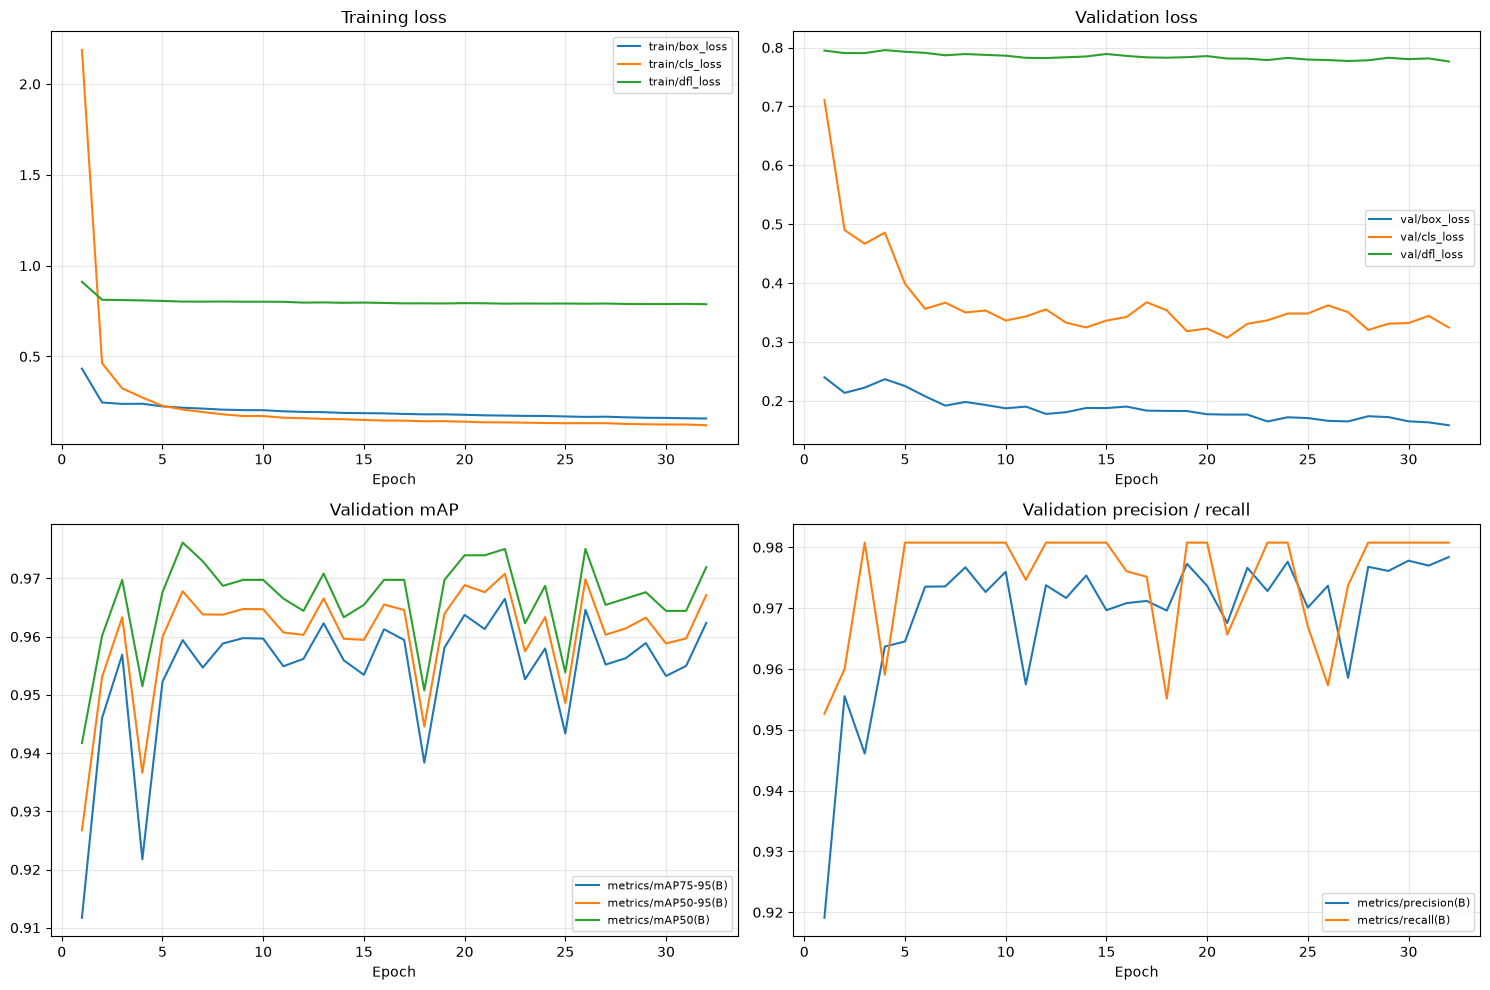

fold 1 학습 곡선


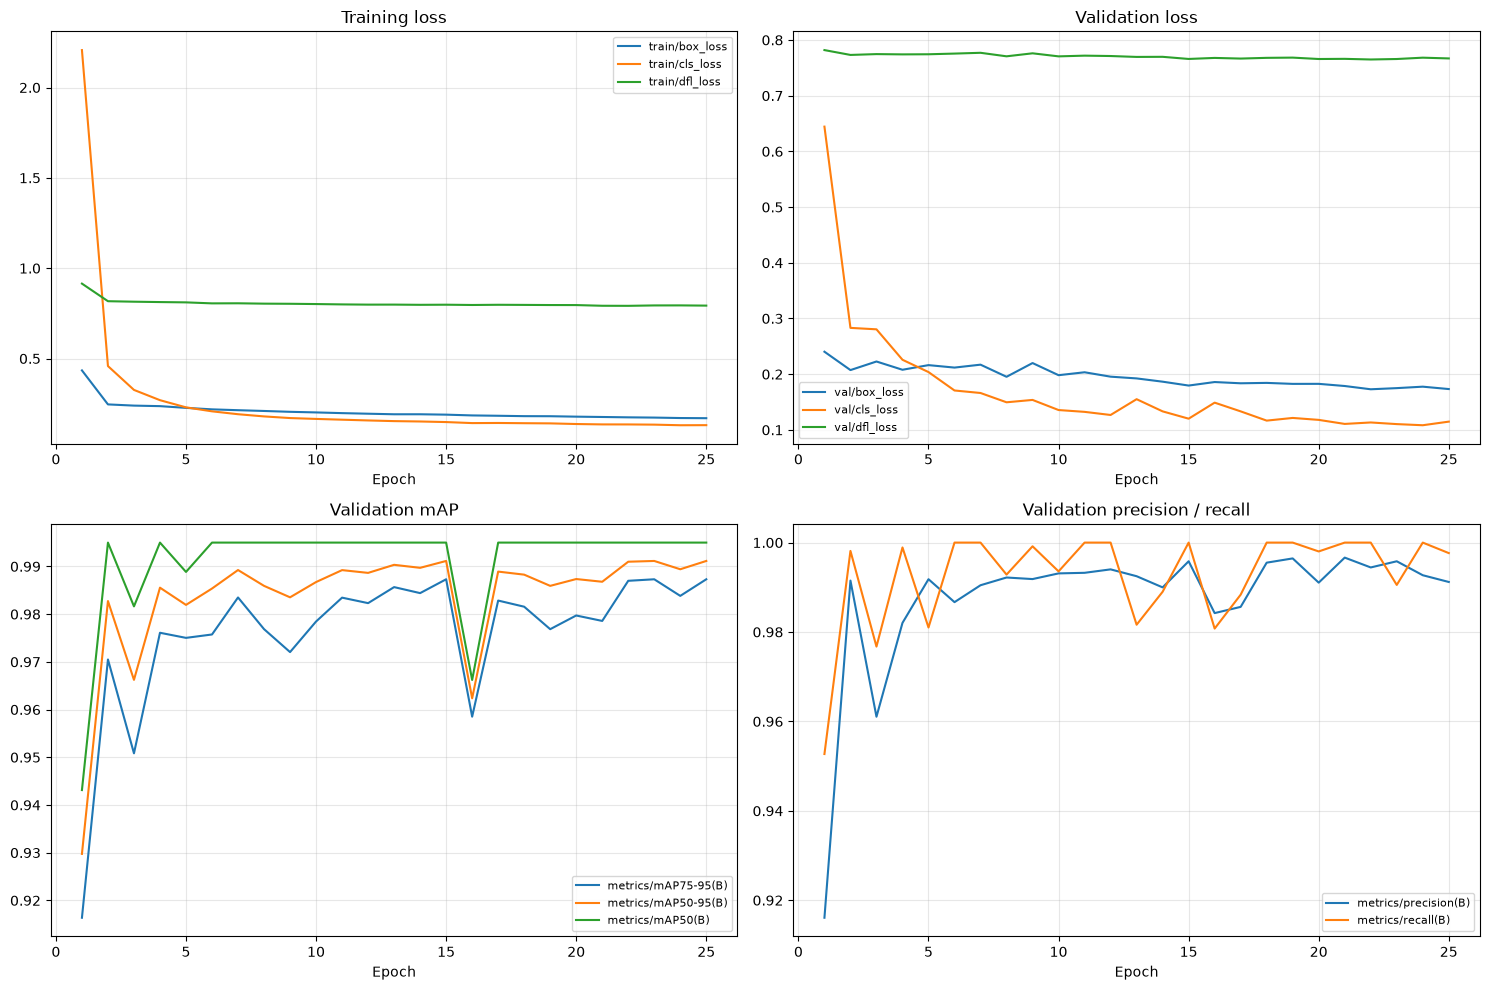

fold 2 학습 곡선


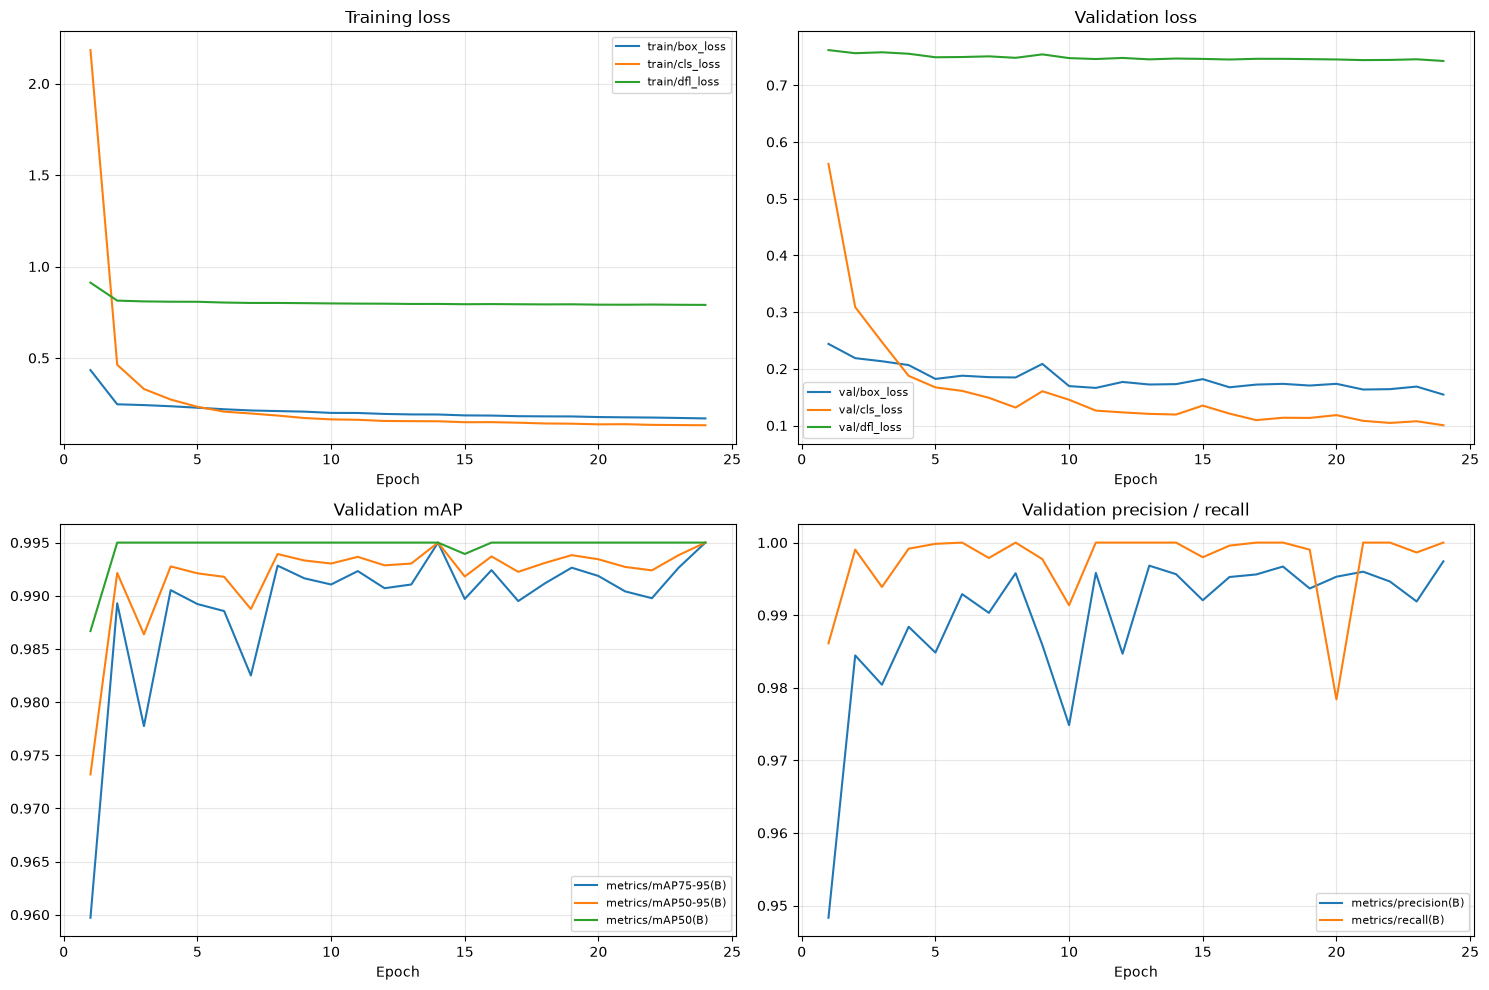

fold 3 학습 곡선


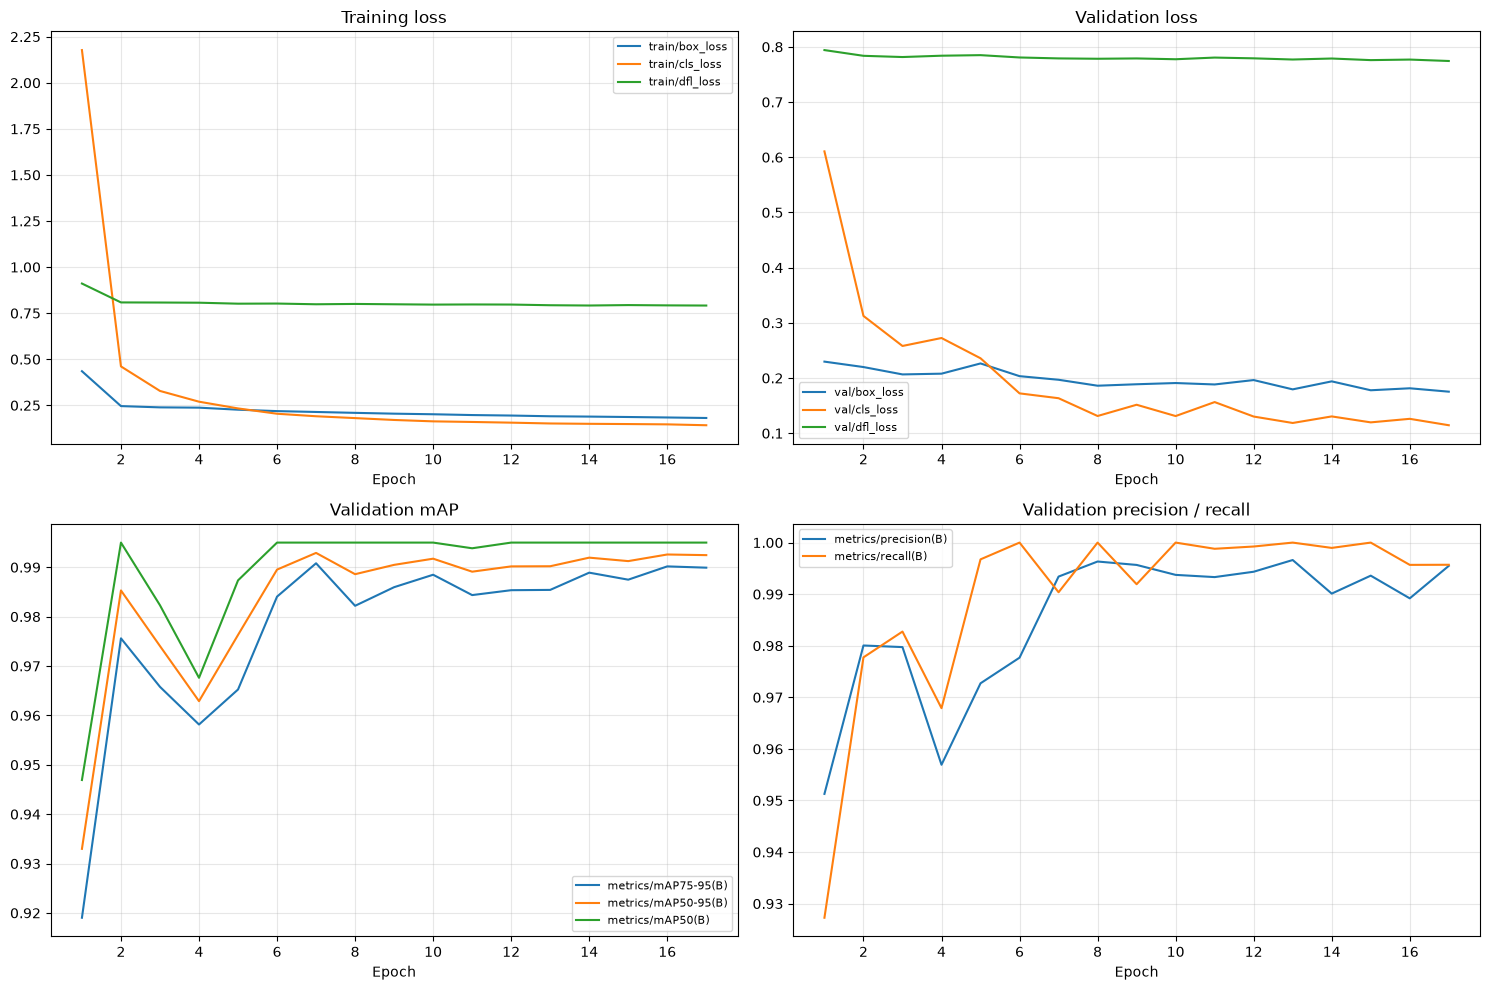

fold 4 학습 곡선


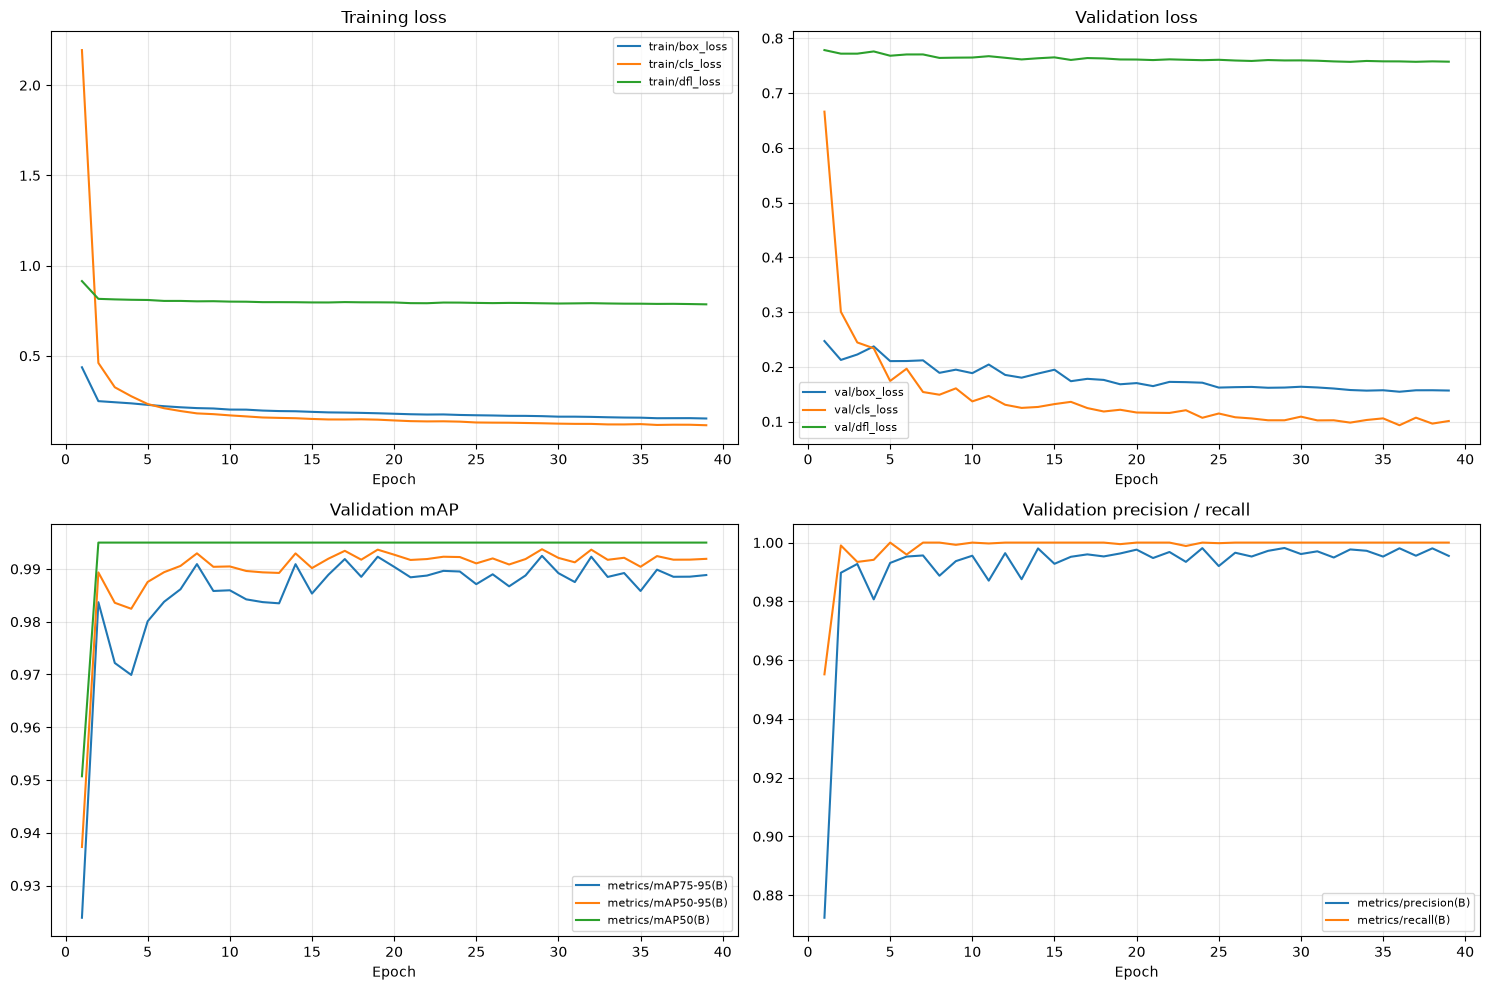

In [24]:
for fold, yolo_checkpoint in checkpoints.items():
    validation_dir = validation_dirs[fold]
    print(f"fold {fold} 학습 곡선")
    history = pd.read_csv(yolo_checkpoint.parent.parent / "results.csv")
    history.columns = history.columns.str.strip()
    figure, axes = plt.subplots(2, 2, figsize=(15, 10))
    graphs = [
        (["train/box_loss", "train/cls_loss", "train/dfl_loss"], "Training loss"),
        (["val/box_loss", "val/cls_loss", "val/dfl_loss"], "Validation loss"),
        (["metrics/mAP75-95(B)", "metrics/mAP50-95(B)", "metrics/mAP50(B)"], "Validation mAP"),
        (["metrics/precision(B)", "metrics/recall(B)"], "Validation precision / recall"),
    ]
    for axis, (columns, title) in zip(axes.flat, graphs, strict=True):
        for column in columns:
            axis.plot(history["epoch"], history[column], label=column)
        axis.set(title=title, xlabel="Epoch")
        axis.grid(alpha=0.3)
        axis.legend(fontsize=8)
    figure.tight_layout()
    figure.savefig(validation_dir / "training_validation_curves.png", dpi=160)
    display(figure)
    plt.close(figure)

fold 0 혼동행렬
Ultralytics 8.4.182 🚀 Python-3.12.15 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4070 Ti SUPER, 16376MiB)
YOLO11m summary (fused): 125 layers, 20,104,048 parameters, 0 gradients, 68.2 GFLOPs
val: Fast image access ✅ (ping: 2.2±0.6 ms, read: 266.3±32.7 MB/s, size: 1661.5 KB)
val: Scanning /mnt/c/AI/test/pill-bbox/data/processed/yolo/v1/labels/train... 37 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 37/37 332.3it/s 0.1s.0s
val: New cache created: /mnt/c/AI/test/pill-bbox/data/processed/yolo/v1/labels/train.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 6.2it/s 0.8s0.2s
                   all         37        117      0.981      0.981      0.975      0.971
           일양하이트린정 2mg         31         31          1          1      0.995      0.989
    기넥신에프정(은행엽엑스)(수출용)          6          6          1          1      0.995      0.995
          뉴로메드정(옥시라세탐)          5          5          1          1 

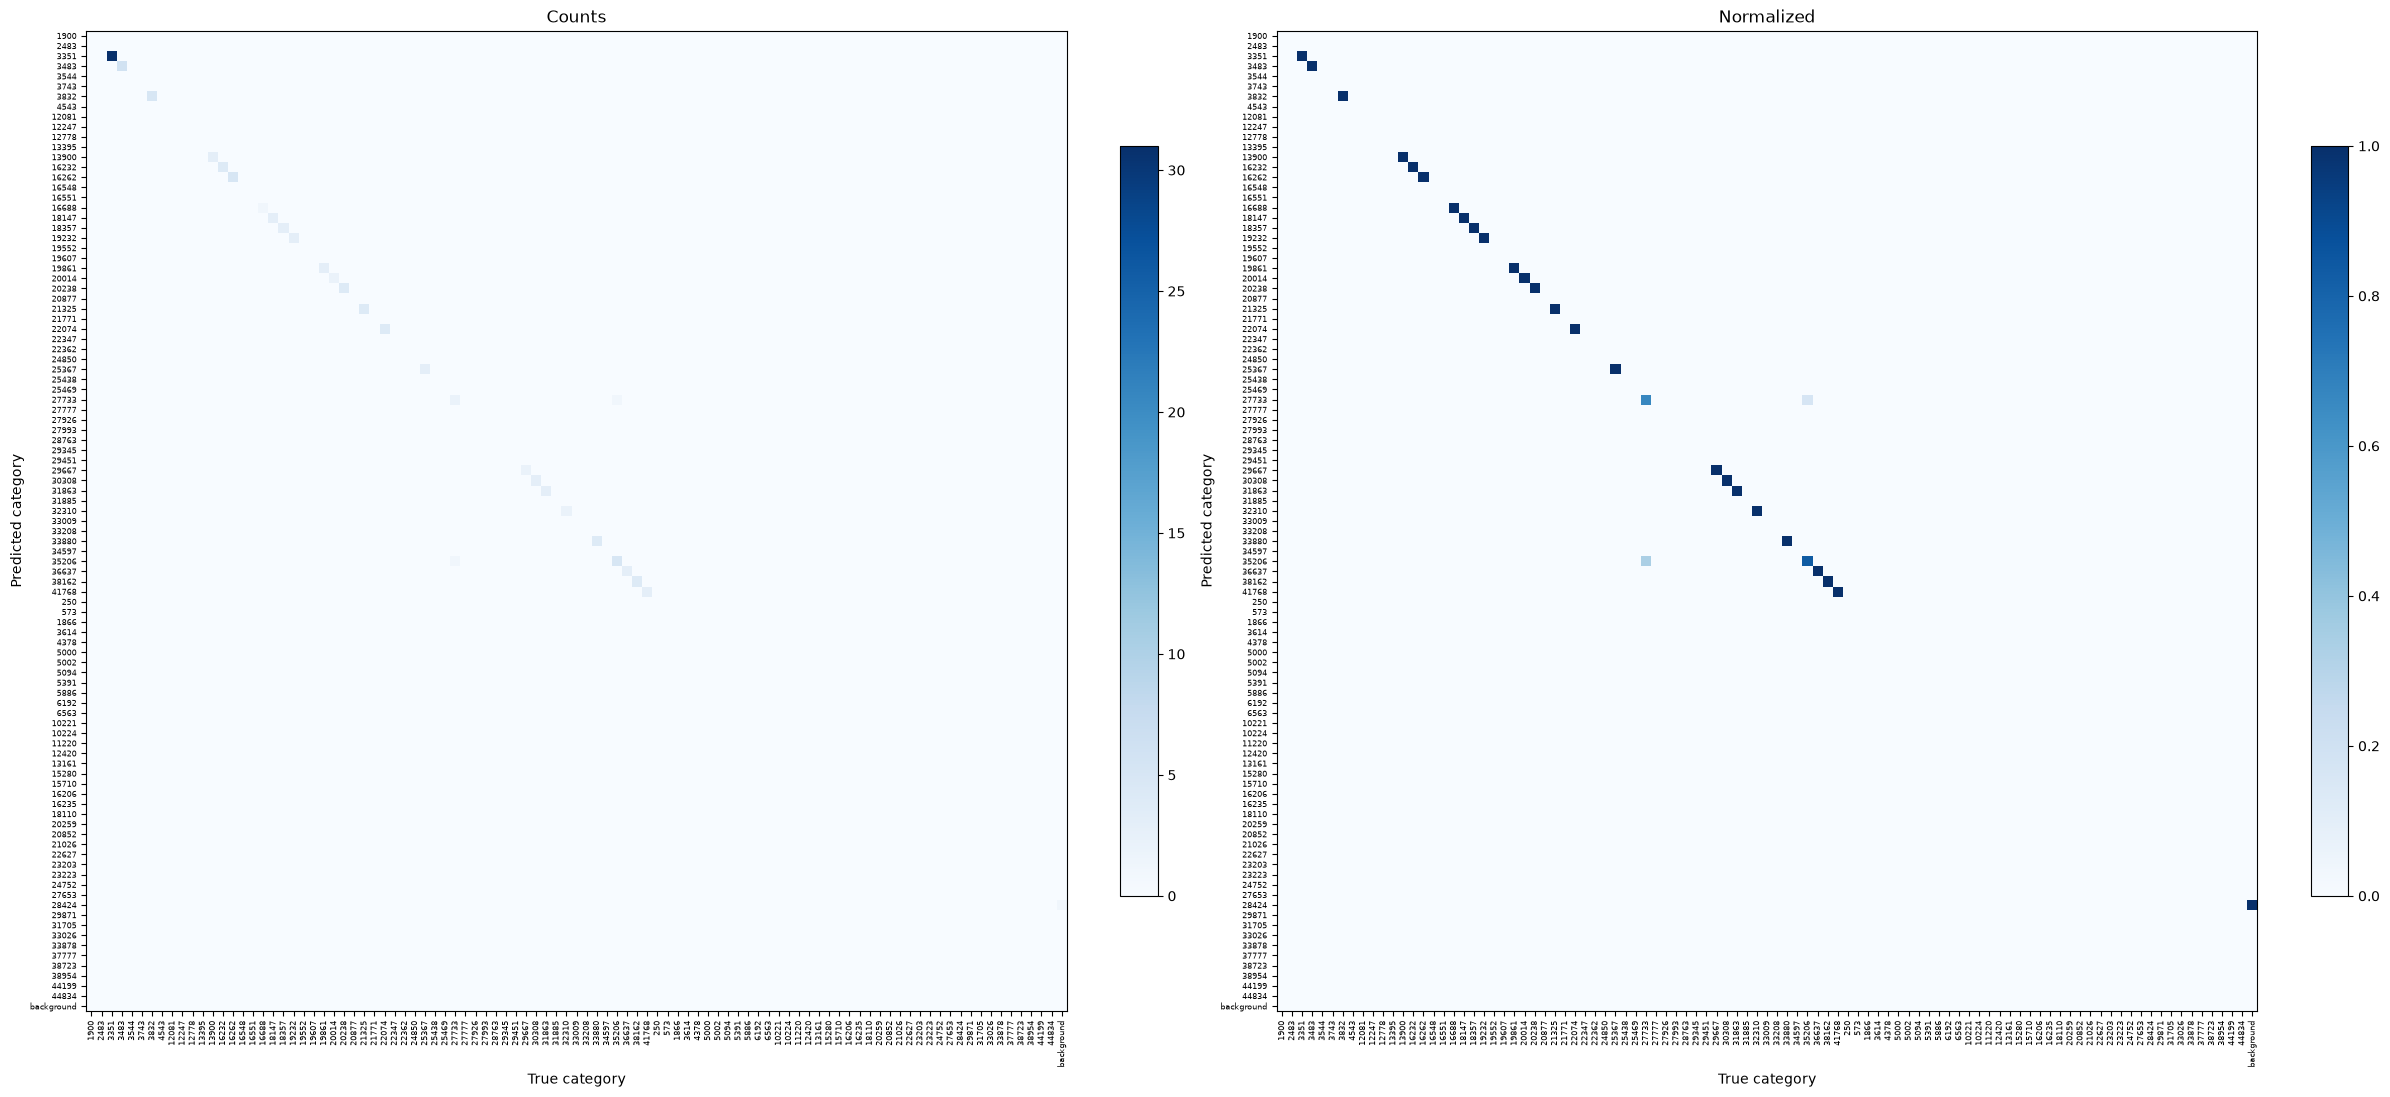

혼동행렬 저장: /mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100_aihub_class/yolo11m_v5_s42/yolo/combofix_v1_s42_MuSGD_lr0.001_e100_fold0/validation_20261104_170852_612467
fold 1 혼동행렬
Ultralytics 8.4.182 🚀 Python-3.12.15 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4070 Ti SUPER, 16376MiB)
YOLO11m summary (fused): 125 layers, 20,104,048 parameters, 0 gradients, 68.2 GFLOPs
val: Fast image access ✅ (ping: 2.1±0.8 ms, read: 281.3±19.9 MB/s, size: 1723.9 KB)
val: Scanning /mnt/c/AI/test/pill-bbox/data/processed/yolo/v1/labels/train... 39 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 39/39 306.0it/s 0.1s.2s
val: New cache created: /mnt/c/AI/test/pill-bbox/data/processed/yolo/v1/labels/train.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 5.0it/s 1.0s0.6s
                   all         39        123      0.998          1      0.995      0.991
           일양하이트린정 2mg         33         33          1          1      0.995     

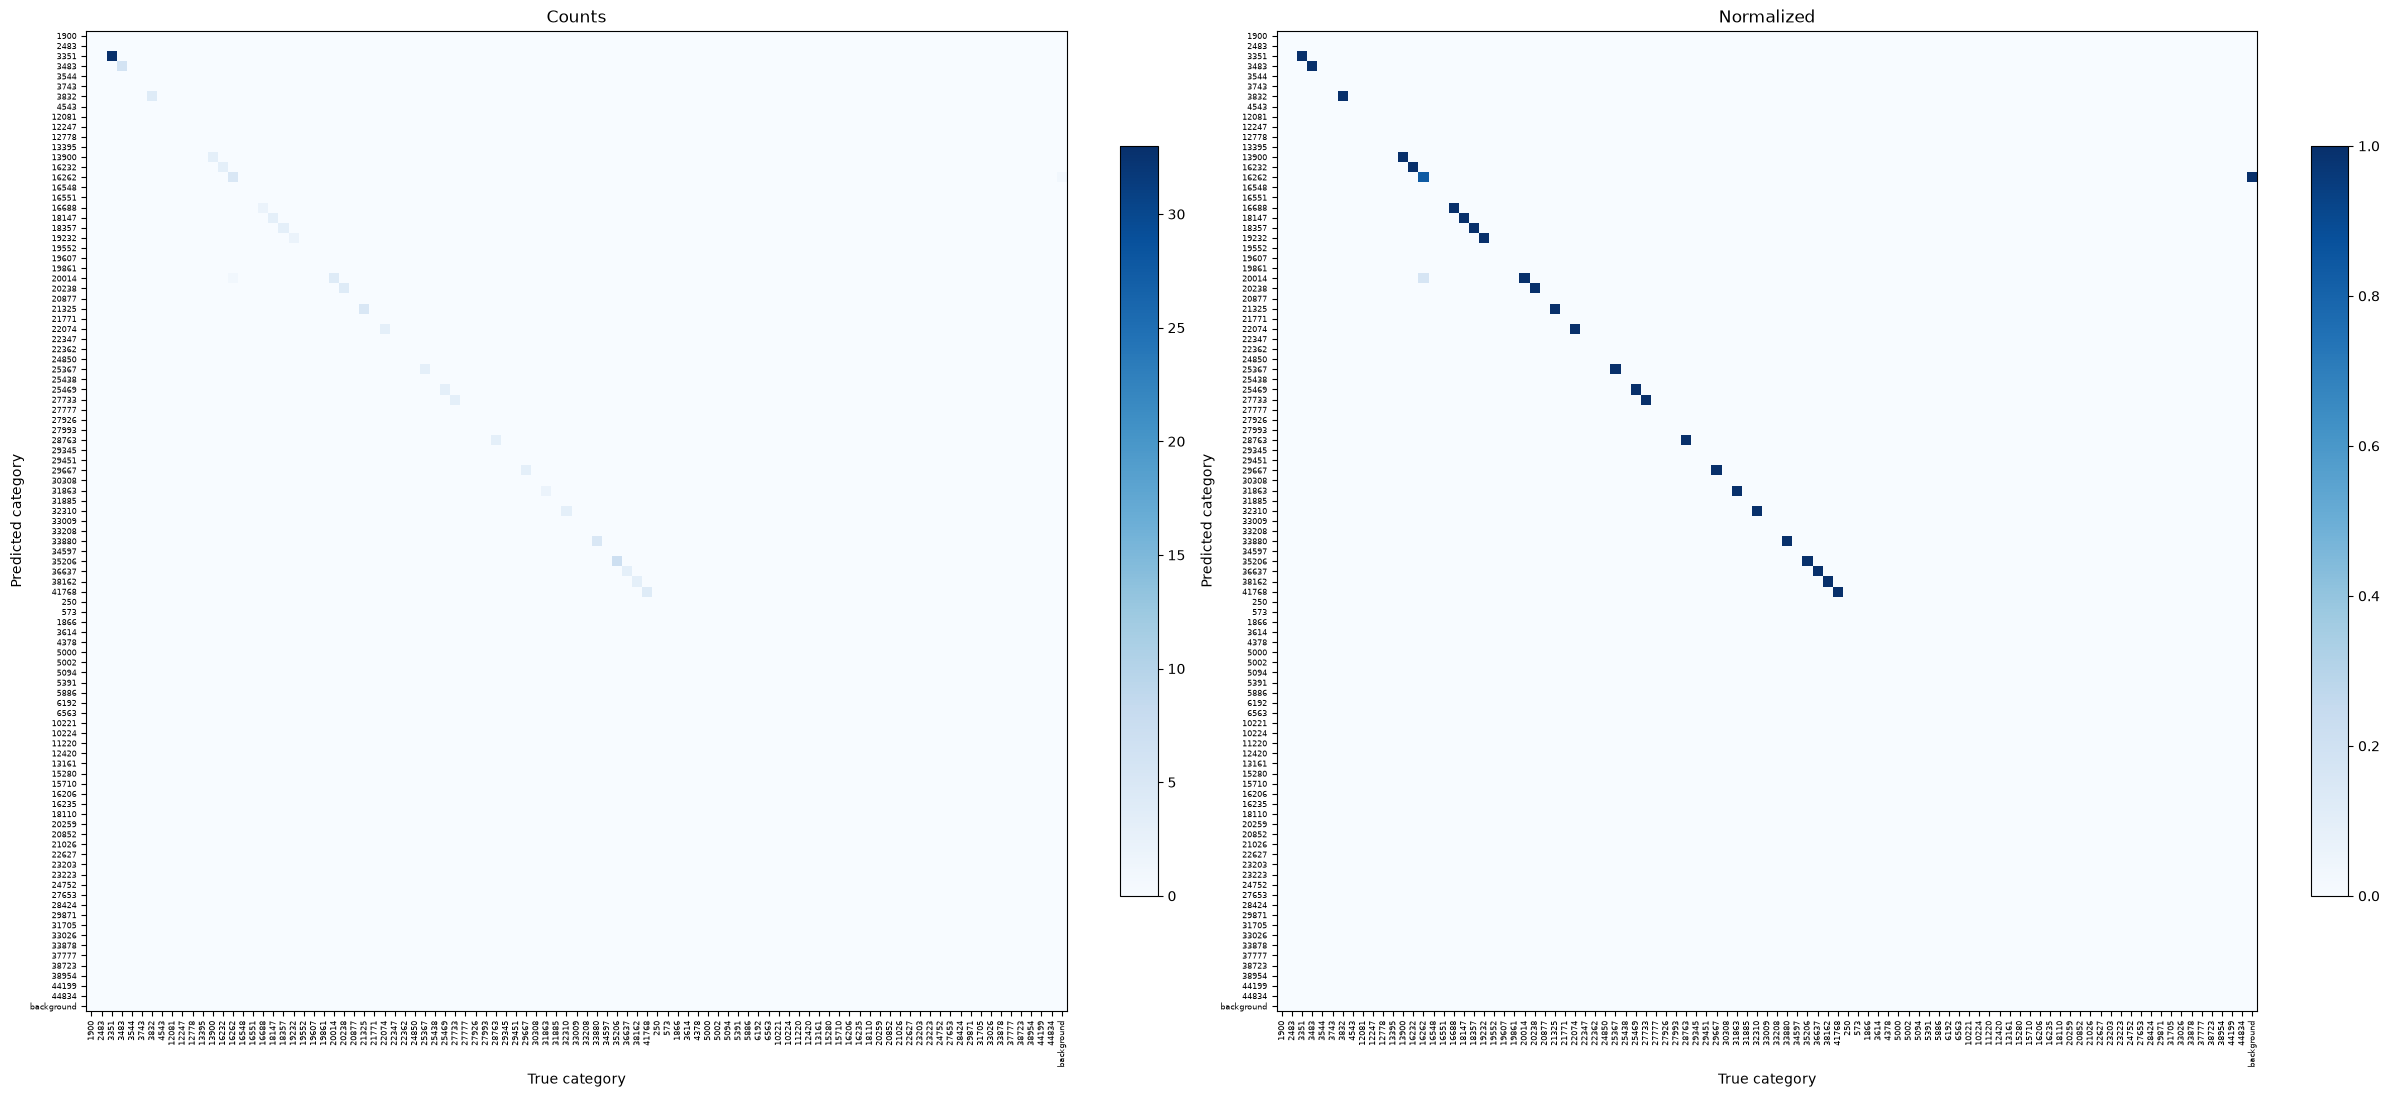

혼동행렬 저장: /mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100_aihub_class/yolo11m_v5_s42/yolo/combofix_v1_s42_MuSGD_lr0.001_e100_fold1/validation_20261104_170854_799055
fold 2 혼동행렬
Ultralytics 8.4.182 🚀 Python-3.12.15 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4070 Ti SUPER, 16376MiB)
YOLO11m summary (fused): 125 layers, 20,104,048 parameters, 0 gradients, 68.2 GFLOPs
val: Fast image access ✅ (ping: 1.8±0.2 ms, read: 258.5±42.7 MB/s, size: 1764.9 KB)
val: Scanning /mnt/c/AI/test/pill-bbox/data/processed/yolo/v1/labels/train... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 332.7it/s 0.1s.1s
val: New cache created: /mnt/c/AI/test/pill-bbox/data/processed/yolo/v1/labels/train.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 4.5it/s 1.1s0.5s
                   all         40        129          1          1      0.995      0.995
           일양하이트린정 2mg         31         31          1          1      0.995     

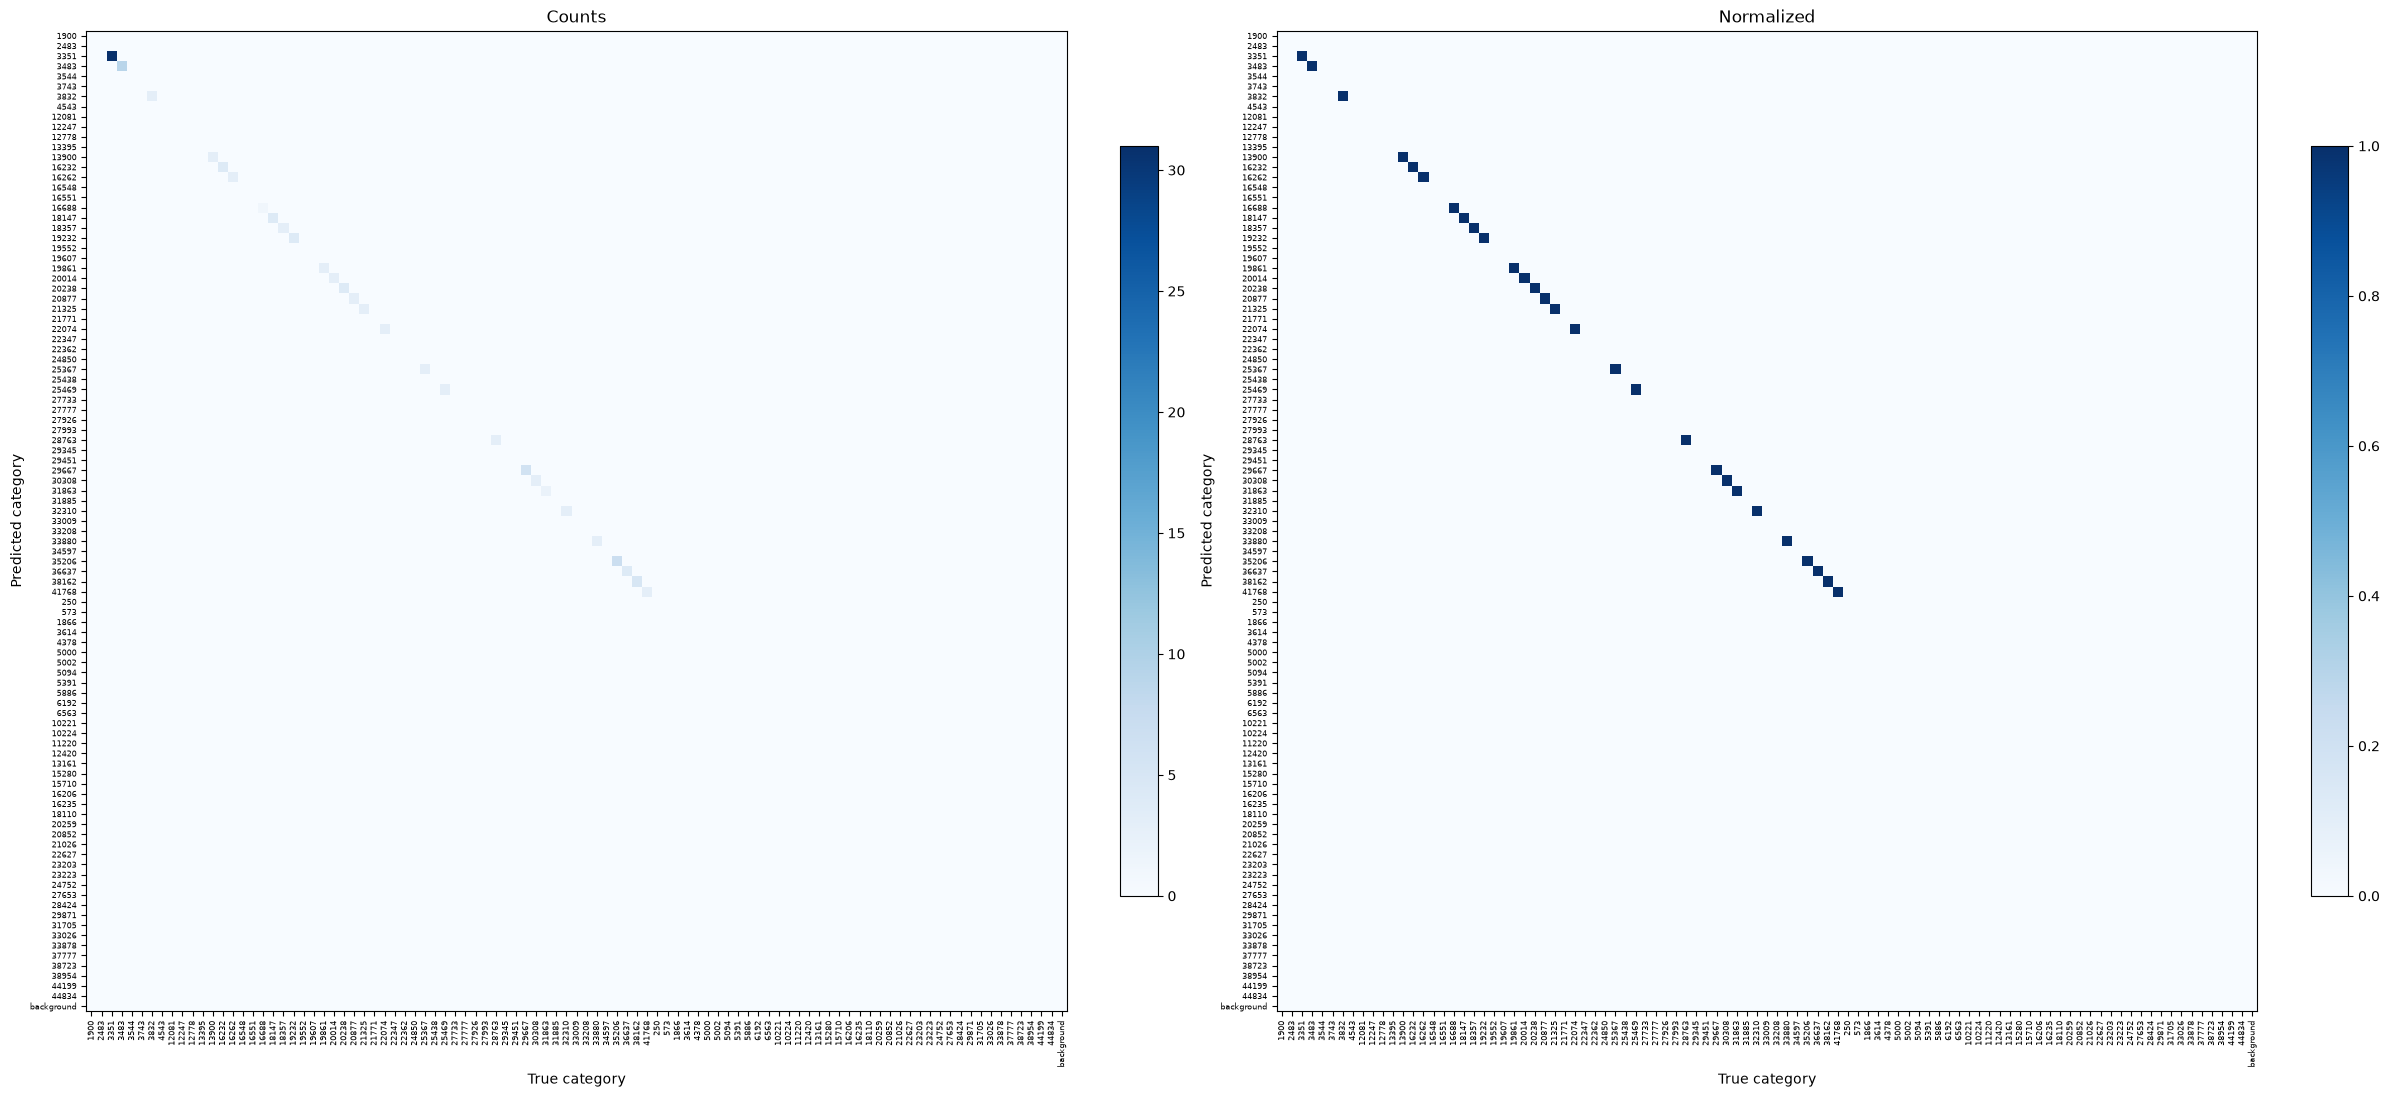

혼동행렬 저장: /mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100_aihub_class/yolo11m_v5_s42/yolo/combofix_v1_s42_MuSGD_lr0.001_e100_fold2/validation_20261104_170856_416987
fold 3 혼동행렬
Ultralytics 8.4.182 🚀 Python-3.12.15 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4070 Ti SUPER, 16376MiB)
YOLO11m summary (fused): 125 layers, 20,104,048 parameters, 0 gradients, 68.2 GFLOPs
val: Fast image access ✅ (ping: 2.0±0.6 ms, read: 281.3±23.4 MB/s, size: 1659.1 KB)
val: Scanning /mnt/c/AI/test/pill-bbox/data/processed/yolo/v1/labels/train... 38 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 38/38 297.2it/s 0.1s.2s
val: New cache created: /mnt/c/AI/test/pill-bbox/data/processed/yolo/v1/labels/train.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 4.1it/s 1.2s0.6ss
                   all         38        120          1          1      0.995      0.993
           일양하이트린정 2mg         32         32          1          1      0.995    

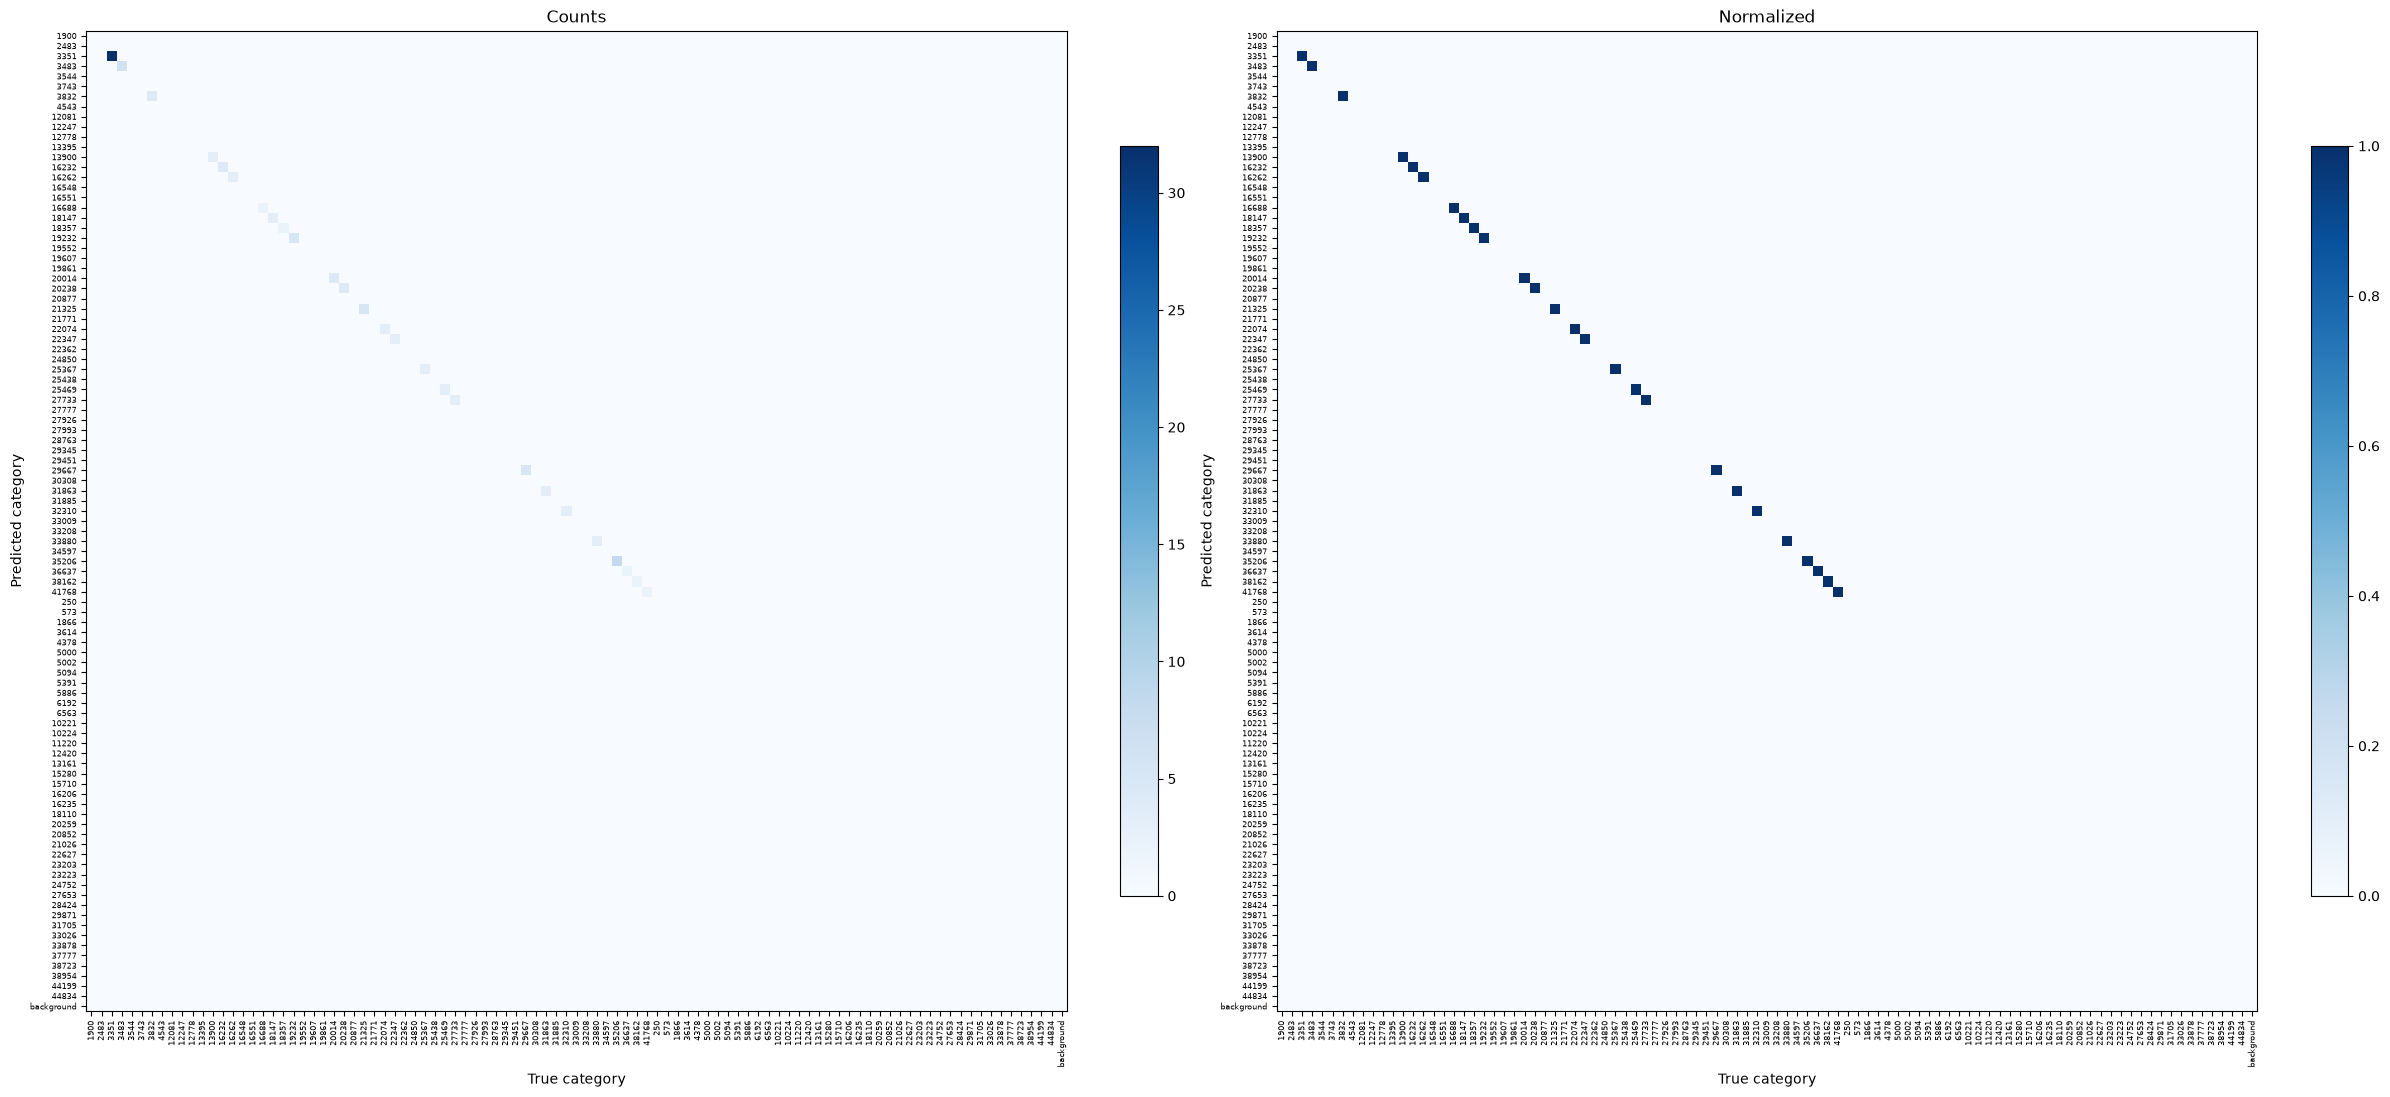

혼동행렬 저장: /mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100_aihub_class/yolo11m_v5_s42/yolo/combofix_v1_s42_MuSGD_lr0.001_e100_fold3/validation_20261104_170858_049931
fold 4 혼동행렬
Ultralytics 8.4.182 🚀 Python-3.12.15 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4070 Ti SUPER, 16376MiB)
YOLO11m summary (fused): 125 layers, 20,104,048 parameters, 0 gradients, 68.2 GFLOPs
val: Fast image access ✅ (ping: 2.0±0.5 ms, read: 288.5±19.0 MB/s, size: 1697.1 KB)
val: Scanning /mnt/c/AI/test/pill-bbox/data/processed/yolo/v1/labels/train... 39 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 39/39 307.8it/s 0.1s.2s
val: New cache created: /mnt/c/AI/test/pill-bbox/data/processed/yolo/v1/labels/train.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 6.0it/s 0.8s0.2s
                   all         39        126          1          1      0.995      0.994
           일양하이트린정 2mg         30         30          1          1      0.995     

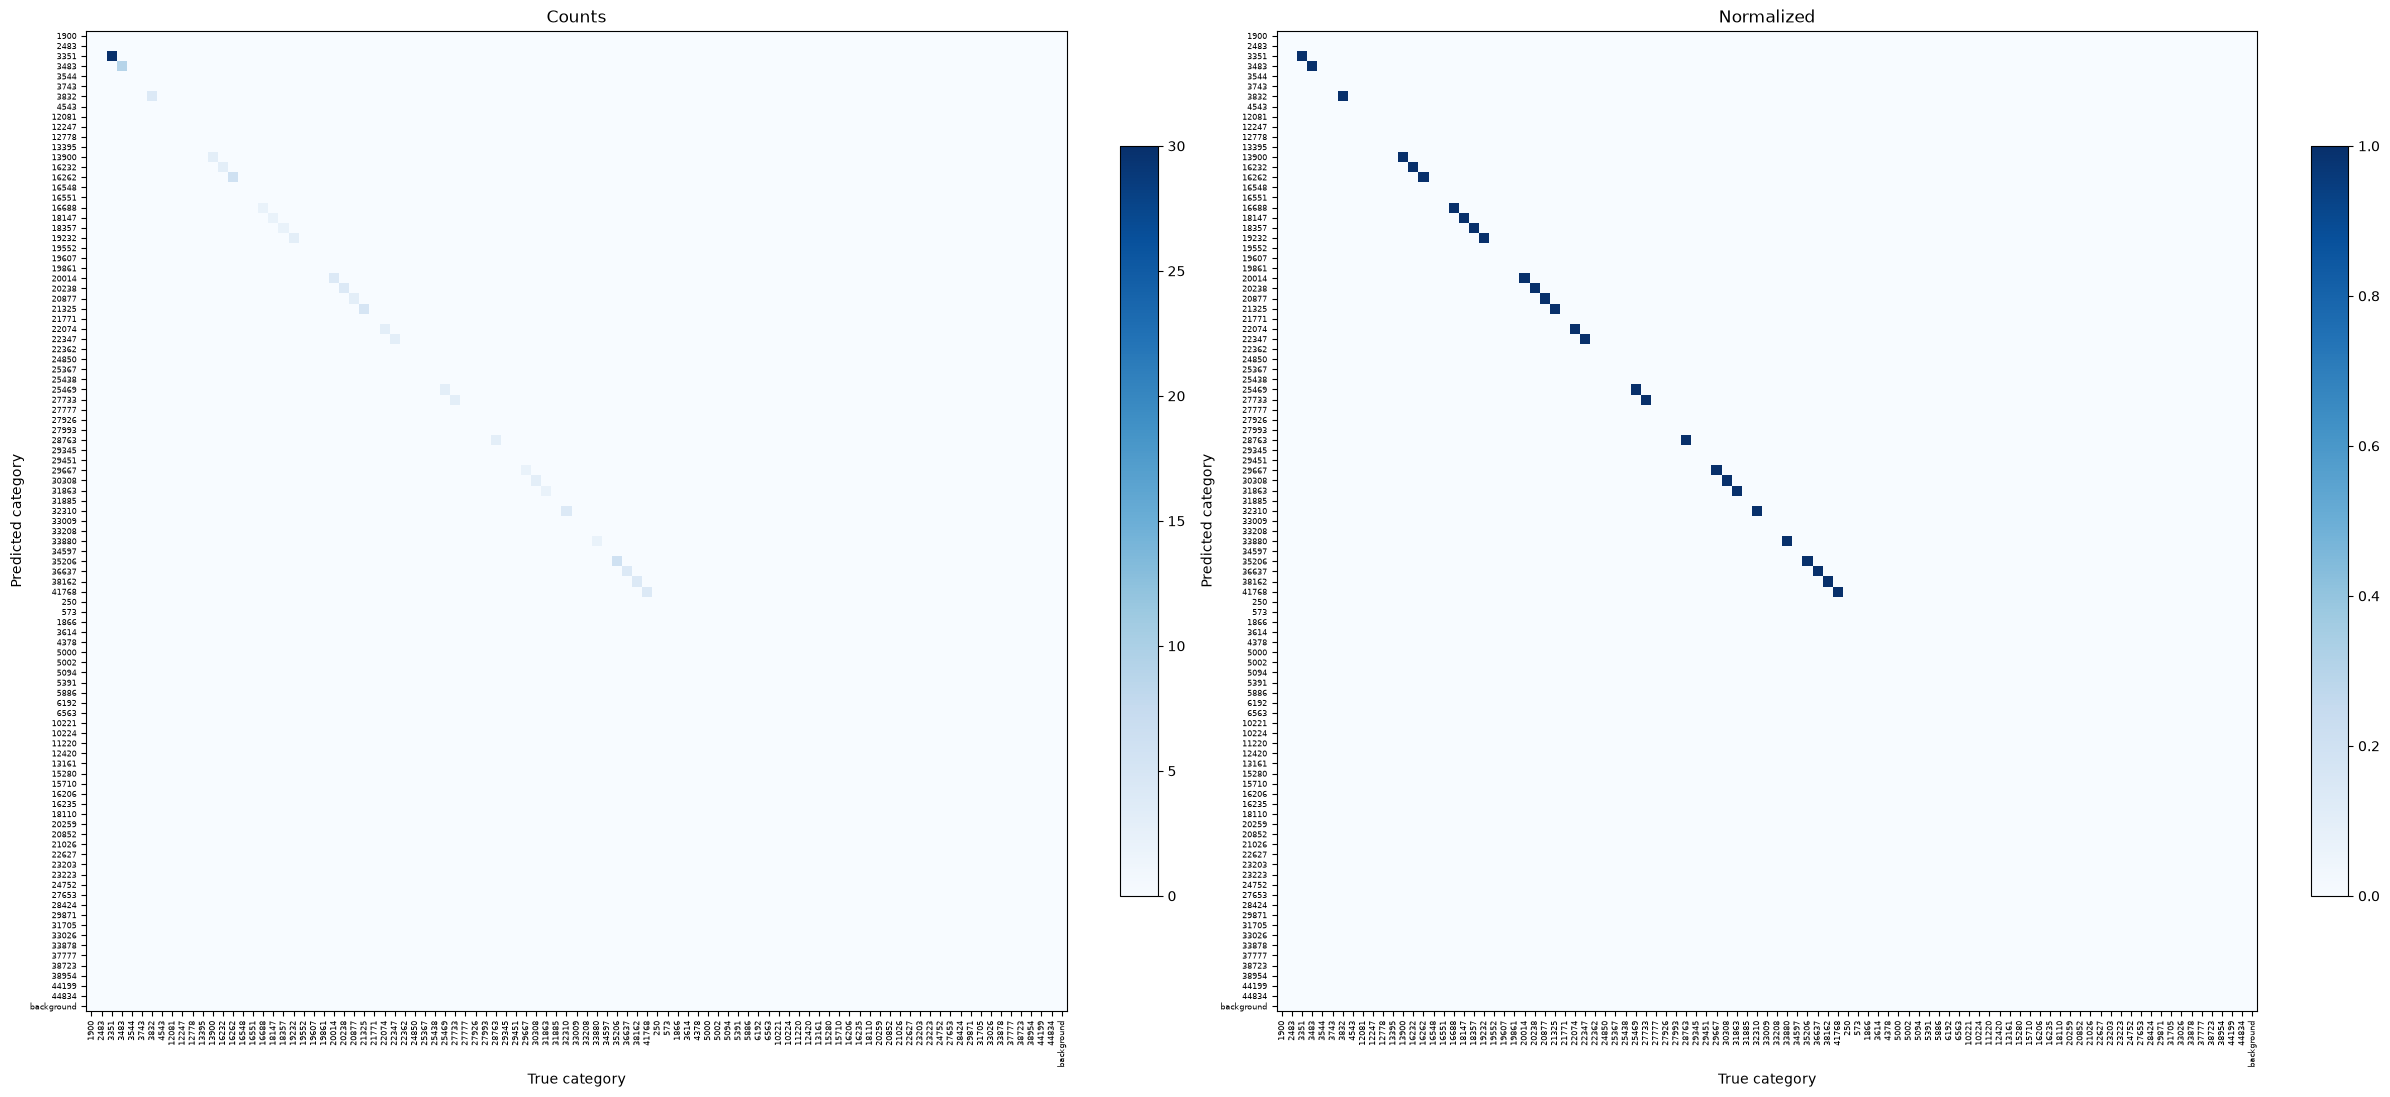

혼동행렬 저장: /mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100_aihub_class/yolo11m_v5_s42/yolo/combofix_v1_s42_MuSGD_lr0.001_e100_fold4/validation_20261104_170859_624169


In [25]:
from ultralytics.models.yolo.detect import DetectionValidator


def capture_confusion(validator: DetectionValidator) -> None:
    """검증이 끝나면 검출 혼동행렬을 복사한다."""
    confusion_state["matrix"] = validator.confusion_matrix.matrix.copy()


for fold, yolo_checkpoint in checkpoints.items():
    validation_dir = validation_dirs[fold]
    validation_model = YOLO(yolo_checkpoint)
    confusion_state = {}
    print(f"fold {fold} 혼동행렬")
    validation_model.add_callback("on_val_end", capture_confusion)
    try:
        validation_model.val(
            data=str(fold_data_paths[fold]),
            split="val",
            imgsz=IMGSZ,
            batch=BATCH,
            conf=CM_CONF,
            iou=NMS_IOU,
            max_det=MAX_DET,
            device=get_device(),
            plots=True,
            project=str(validation_dir),
            name="confusion",
            exist_ok=True,
        )
    finally:
        validation_model.callbacks["on_val_end"].remove(capture_confusion)
    counts = confusion_state["matrix"]
    labels = class_map.sort_values("yolo_idx")["category_id"].astype(str).tolist() + ["background"]
    normalized = counts / np.maximum(counts.sum(axis=0, keepdims=True), 1)
    pd.DataFrame(counts, index=labels, columns=labels).to_csv(validation_dir / "confusion_yolo.csv")
    pd.DataFrame(normalized, index=labels, columns=labels).to_csv(
        validation_dir / "confusion_yolo_normalized.csv"
    )
    figure, axes = plt.subplots(1, 2, figsize=(24, 12))
    for axis, values, title in zip(
        axes, [counts, normalized], ["Counts", "Normalized"], strict=True
    ):
        shown = axis.imshow(values, cmap="Blues", vmin=0, vmax=1 if title == "Normalized" else None)
        axis.set(title=title, xlabel="True category", ylabel="Predicted category")
        axis.set_xticks(range(len(labels)), labels, rotation=90, fontsize=6)
        axis.set_yticks(range(len(labels)), labels, fontsize=6)
        figure.colorbar(shown, ax=axis, fraction=0.035)
    figure.tight_layout()
    figure.savefig(validation_dir / "confusion_yolo.png", dpi=160)
    display(figure)
    plt.close(figure)
    print("혼동행렬 저장:", validation_dir.resolve())

## 10. fold별 test 예측 · 로컬 제출 CSV
각 fold의 best.pt로 test를 따로 예측합니다. 결과를 합치거나 평균하지 않습니다. 한 제출 폴더에 fold별 CSV·예측 원본·모델 경로 기록을 모아 저장합니다.


In [26]:
from models.evaluate import PRED_COLS, to_submission

submission_dir = experiment_dir / f"submissions_{datetime.now():%Y%m%d_%H%M%S_%f}"
submission_dir.mkdir(parents=True, exist_ok=False)
submission_rows = []
for fold, yolo_checkpoint in checkpoints.items():
    to_category = dict(zip(class_map["yolo_idx"], class_map["category_id"], strict=True))
    prediction_rows = []
    for result in YOLO(yolo_checkpoint).predict(
        source=str(yolo_dir(LABEL) / "images/test"),
        imgsz=IMGSZ,
        conf=EVAL_CONF,
        iou=NMS_IOU,
        max_det=MAX_DET,
        device=get_device(),
        stream=True,
        verbose=False,
    ):
        for (x1, y1, x2, y2), index, score in zip(
            result.boxes.xyxy.tolist(),
            result.boxes.cls.int().tolist(),
            result.boxes.conf.tolist(),
            strict=True,
        ):
            prediction_rows.append(
                [
                    Path(result.path).name,
                    index,
                    to_category[index],
                    x1,
                    y1,
                    x2 - x1,
                    y2 - y1,
                    score,
                ]
            )
    predictions = pd.DataFrame(prediction_rows, columns=PRED_COLS)
    if predictions.empty:
        raise ValueError("test 예측 박스가 없습니다. 예측 결과와 설정을 확인하세요.")
    predictions.to_csv(submission_dir / f"fold{fold}_yolo_predictions.csv", index=False)
    submission = to_submission(predictions)
    submission_path = submission_dir / f"fold{fold}_submission_yolo.csv"
    submission.to_csv(submission_path, index=False)
    (submission_dir / f"fold{fold}_prediction_config.json").write_text(
        json.dumps(
            {
                "yolo_weights": str(yolo_checkpoint.resolve()),
                "fold": fold,
                "imgsz": IMGSZ,
                "conf": EVAL_CONF,
                "nms_iou": NMS_IOU,
                "max_det": MAX_DET,
            },
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )
    print(f"fold {fold} YOLO 단독 제출 CSV:", submission_path.resolve())
    display(submission.head())
    submission_rows.append(
        {
            "fold": fold,
            "csv": str(submission_path.resolve()),
            "weights": str(yolo_checkpoint.resolve()),
        }
    )

submission_index = pd.DataFrame(submission_rows).sort_values("fold")
submission_index.to_csv(submission_dir / "submission_index.csv", index=False)
display(submission_index)
print("fold별 제출 CSV 폴더:", submission_dir.resolve())

fold 0 YOLO 단독 제출 CSV: /mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100_aihub_class/yolo11m_v5_s42/submissions_20261104_171001_698954/fold0_submission_yolo.csv


,annotation_id,image_id,category_id,bbox_x,bbox_y,bbox_w,bbox_h,score
0,1,1,1900,156.487732,252.562927,203.568237,123.836975,0.969435
1,2,1,16551,553.552185,73.768509,405.356445,400.110336,0.959728
2,3,1,24850,169.881882,740.999023,183.729019,291.494629,0.956654
3,4,1,27926,599.519653,671.357788,252.933594,482.165894,0.947186
4,5,3,1900,139.916153,242.900238,198.944443,126.393555,0.968284


fold 1 YOLO 단독 제출 CSV: /mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100_aihub_class/yolo11m_v5_s42/submissions_20261104_171001_698954/fold1_submission_yolo.csv


,annotation_id,image_id,category_id,bbox_x,bbox_y,bbox_w,bbox_h,score
0,1,1,16551,557.688660,72.500366,402.755859,402.688171,0.983895
1,2,1,24850,172.951904,740.384033,180.314209,291.250854,0.963457
2,3,1,1900,156.460510,251.472824,204.514404,125.333511,0.961038
3,4,1,27926,601.949707,671.402588,251.774658,485.068481,0.949552
4,5,3,16551,527.218994,64.616089,389.477173,392.546570,0.984595


fold 2 YOLO 단독 제출 CSV: /mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100_aihub_class/yolo11m_v5_s42/submissions_20261104_171001_698954/fold2_submission_yolo.csv


,annotation_id,image_id,category_id,bbox_x,bbox_y,bbox_w,bbox_h,score
0,1,1,1900,160.312424,252.095795,202.319351,124.602417,0.971413
1,2,1,24850,171.861450,740.814453,181.676086,290.614258,0.969083
2,3,1,16551,554.777100,69.996994,407.313232,405.423233,0.961099
3,4,1,27926,601.057739,671.968506,254.612061,477.750732,0.960082
4,5,3,24850,139.355347,703.077881,186.807373,293.307617,0.964263


... (2 outputs left out)

fold 4 YOLO 단독 제출 CSV: /mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100_aihub_class/yolo11m_v5_s42/submissions_20261104_171001_698954/fold4_submission_yolo.csv


,annotation_id,image_id,category_id,bbox_x,bbox_y,bbox_w,bbox_h,score
0,1,1,24850,171.171600,739.346924,182.292419,291.638550,0.955022
1,2,1,27926,602.224487,672.032959,251.228027,482.187256,0.950487
2,3,1,1900,156.268372,252.762146,205.681396,123.692871,0.950137
3,4,1,16551,553.703125,73.974960,403.728760,401.388565,0.942390
4,5,3,1900,143.177475,241.769592,195.875259,128.608276,0.976877


,fold,csv,weights
0,0,/mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100...,/mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100...
1,1,/mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100...,/mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100...
2,2,/mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100...,/mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100...
3,3,/mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100...,/mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100...
4,4,/mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100...,/mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100...


fold별 제출 CSV 폴더: /mnt/c/AI/test/pill-bbox/runs/yolo11m_epoch100_aihub_class/yolo11m_v5_s42/submissions_20261104_171001_698954
